<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:18px; padding:30px 18px 24px; margin-bottom:14px;">
<div style="font-size:11px; letter-spacing:5px; color:#ffd0d0;">M.I.A ROBOTICS · ENGINEERING BETTER ROV SYSTEMS</div>
<h1 style="color:#ffffff; margin:10px 0 6px; border:none;">ROV Video Streaming Workshop</h1>
<div style="font-size:15px; color:#ffe6e6;">Hands-on notebook · measure first, compress smart, stream only what the pilot needs</div>
</div>

This notebook is the practical half of the workshop. Every experiment follows the same pattern:

1. **Question.** What are we trying to find out?
2. **Theory.** Just enough to predict the answer *before* we run anything.
3. **Experiment.** A real measurement using FFmpeg and Python.
4. **Result.** A table and/or chart.
5. **Interpretation.** What this means for *your* ROV.
6. **Exercises.** For you to do, alone or in your team.

> **The rule of this notebook:** *we never trust a number we did not measure.* Where a value is an estimate (for example, a latency budget), it is labelled **ESTIMATE** and the notebook tells you how to measure it on the real vehicle.

<div align="center">

| # | Experiment | Runs on a normal laptop? |
|---|---|---|
| 0 | Setup and the test clip | ✅ |
| 1 | Raw video bandwidth | ✅ |
| 2 | First FFmpeg encodes (H.264, H.265, MJPEG, AV1) | ✅ |
| 3 | CRF vs bitrate targets | ✅ |
| 4 | Encoder presets | ✅ |
| 5 | GOP, keyframes and packet loss | ✅ |
| 6 | Objective quality: PSNR, SSIM, VMAF | ✅ (VMAF only if your FFmpeg has `libvmaf`) |
| 7 | Eight-camera ROV simulator | ✅ |
| 8 | Main streams, substreams, priorities | ✅ |
| 9 | Latency | ✅ (PyAV part optional) |
| 10 | Hardware encoding | ⚠️ Jetson Nano / Raspberry Pi 5 / GPU-specific parts are clearly marked |
| 11 | Final optimization challenge | ✅ |

</div>


**Expected run time** on a 4-core laptop: about 5–10 minutes for the whole notebook. Results are cached in `work/`, so re-running is fast.

<div align="center">

## Installation

</div>


You need **Python 3.10+** and **FFmpeg 5 or newer** (with `libx264`; `libx265` and `libsvtav1` are optional).

```bash
# Ubuntu / Debian / Raspberry Pi OS / Jetson (JetPack)
sudo apt install ffmpeg python3-venv
python3 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt          # numpy pandas matplotlib scipy jupyterlab ipywidgets av
jupyter lab ROV_Video_Streaming_Workshop.ipynb
```

On **Windows**, install FFmpeg from <https://ffmpeg.org/download.html> (a "full" build includes x264/x265/SVT-AV1) and make sure `ffmpeg` is on your `PATH`. On **macOS**: `brew install ffmpeg`.

`av` (PyAV) and `ipywidgets` are optional: Experiment 9 uses PyAV to measure encoder delay frame-by-frame, and Experiment 7 uses ipywidgets for sliders. Everything else works without them.

<div align="center">

## 0. Setup

</div>


The first cell defines small helper functions so the experiments stay readable:

<div align="center">

| Helper | What it does |
|---|---|
| `run(cmd)` | Runs a command and measures **wall-clock time** *and* **CPU time** (so we can compute how many cores an encoder used). |
| `probe(path)` | Calls `ffprobe` and returns codec, resolution, frame rate, duration, bitrate. |
| `packets(path)` | Returns every compressed packet's size, timestamp and keyframe flag. |
| `frame_types(path)` | Returns I/P/B picture types for every frame. |
| `quality(dist, ref)` | Computes PSNR and SSIM of a distorted video against the reference. |

</div>


In [1]:
import os, sys, json, time, shutil, subprocess, resource, re, math, platform, random
from pathlib import Path
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FFMPEG, FFPROBE = shutil.which("ffmpeg"), shutil.which("ffprobe")
assert FFMPEG and FFPROBE, "FFmpeg/ffprobe not found on PATH — see the installation section."

WORK = Path("work"); WORK.mkdir(exist_ok=True)
CPU_CORES = os.cpu_count()

# ---- chart style: one consistent, colour-blind-checked palette -------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CRITICAL = "#c62828"   # reserved for "over the limit" — never used as a series colour
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e2de", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 2)

def run(cmd, check=True):
    """Run a command; return wall time, CPU time (user+sys of the child) and stderr."""
    r0 = resource.getrusage(resource.RUSAGE_CHILDREN); t0 = time.perf_counter()
    p = subprocess.run(cmd, capture_output=True, text=True)
    wall = time.perf_counter() - t0; r1 = resource.getrusage(resource.RUSAGE_CHILDREN)
    cpu = (r1.ru_utime - r0.ru_utime) + (r1.ru_stime - r0.ru_stime)
    if check and p.returncode != 0:
        raise RuntimeError(f"Command failed ({p.returncode}): {' '.join(map(str, cmd))}\n{p.stderr[-1500:]}")
    return {"wall_s": wall, "cpu_s": cpu, "rc": p.returncode, "stderr": p.stderr, "stdout": p.stdout}

def probe(path):
    out = run([FFPROBE, "-v", "error", "-show_streams", "-show_format", "-of", "json", str(path)])["stdout"]
    j = json.loads(out); v = next(s for s in j["streams"] if s["codec_type"] == "video")
    dur = float(j["format"].get("duration", v.get("duration", 0)) or 0)
    size = Path(path).stat().st_size
    return {"codec": v["codec_name"], "profile": v.get("profile"), "pix_fmt": v.get("pix_fmt"),
            "width": v["width"], "height": v["height"], "fps": float(Fraction(v["avg_frame_rate"])) if v["avg_frame_rate"] != "0/0" else None,
            "duration_s": dur, "size_bytes": size, "bitrate_mbps": size * 8 / dur / 1e6 if dur else None}

def packets(path):
    """Per-packet table: pts (s), size (bytes), keyframe flag."""
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "packet=pts_time,size,flags,pos",
               "-of", "csv=p=0", str(path)])["stdout"]
    rows = []
    for line in out.strip().splitlines():
        parts = line.split(",")
        if len(parts) < 4 or parts[0] in ("", "N/A"): continue
        rows.append((float(parts[0]), int(parts[1]), int(parts[2]) if parts[2] not in ("", "N/A") else -1, "K" in parts[3]))
    return pd.DataFrame(rows, columns=["pts", "size", "pos", "key"]).sort_values("pts").reset_index(drop=True)

def frame_types(path):
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "frame=pict_type,pkt_size",
               "-of", "json", str(path)])["stdout"]
    frames = json.loads(out).get("frames", [])
    return pd.DataFrame([(f.get("pict_type", "?"), int(f.get("pkt_size", 0))) for f in frames], columns=["type", "size"])

def quality(dist, ref, width=None, height=None, per_frame=False):
    """PSNR (dB, luma+chroma average) and SSIM (0..1) of `dist` against `ref`.
    The distorted video is scaled back to the reference size first, so substreams can be compared too."""
    info = probe(ref); w, h = width or info["width"], height or info["height"]
    plog, slog = WORK / "psnr.log", WORK / "ssim.log"
    # Timestamps are snapped to the reference frame grid (settb): containers such as MKV store ms-rounded
    # timestamps, and without this every third frame would be compared with the wrong reference frame.
    sync = f"setpts=PTS-STARTPTS,settb=1/{FPS}"
    graph = (f"[0:v]scale={w}:{h}:flags=bicubic,format=yuv420p,{sync},split[d1][d2];"
             f"[1:v]format=yuv420p,{sync},split[r1][r2];"
             f"[d1][r1]psnr=stats_file={plog}[o1];[d2][r2]ssim=stats_file={slog}[o2]")
    ref_in = SRC_IN if Path(ref) == SRC else ["-i", str(ref)]
    r = run([FFMPEG, "-hide_banner", "-i", str(dist), *ref_in, "-lavfi", graph,
             "-map", "[o1]", "-f", "null", "-", "-map", "[o2]", "-f", "null", "-"])
    psnr = float(re.search(r"PSNR .*average:([\d.]+|inf)", r["stderr"]).group(1).replace("inf", "99"))
    ssim = float(re.search(r"SSIM .*All:([\d.]+)", r["stderr"]).group(1))
    if not per_frame:
        return psnr, ssim
    pf = [min(float(m.group(1).replace("inf", "99")), 99) for m in re.finditer(r"psnr_avg:([\d.]+|inf)", plog.read_text())]
    return psnr, ssim, np.array(pf)

def mbps_fmt(x, _=None):
    return f"{x:,.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2f}")

ENCODERS = run([FFMPEG, "-hide_banner", "-encoders"])["stdout"]
FILTERS = run([FFMPEG, "-hide_banner", "-filters"])["stdout"]
HAS = {name: (f" {name} " in ENCODERS) for name in ["libx264", "libx265", "libsvtav1", "libaom-av1", "mjpeg",
                                                   "h264_nvenc", "h264_vaapi", "h264_qsv", "h264_v4l2m2m"]}
HAS["libvmaf"] = " libvmaf " in FILTERS
print(run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0])
print(f"Python {platform.python_version()} on {platform.machine()} · {CPU_CORES} CPU cores")
print("Available:", ", ".join(k for k, v in HAS.items() if v))
print("Missing:  ", ", ".join(k for k, v in HAS.items() if not v) or "—")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
Python 3.13.18 on x86_64 · 2 CPU cores
Available: libx264, libx265, libsvtav1, libaom-av1, mjpeg, h264_nvenc, h264_vaapi, h264_qsv, h264_v4l2m2m
Missing:   libvmaf


<div align="center">

### 0.1 The test clip

</div>


We need a reference video. Ideally this is **real footage from your ROV** — set `ROV_SOURCE` below to a file path and the notebook will cut a 6-second, 1280×720, 30 FPS segment from it.

If no footage is available, the notebook **generates a synthetic "underwater inspection" clip** that has the properties that make underwater video hard to compress:

* **Blue-green colour cast and depth-dependent attenuation** (red light is absorbed first).
* **Moving caustics** — the rippling light patterns near the surface. They change every frame, which defeats temporal prediction.
* **Marine snow** — hundreds of small drifting particles, each one a tiny "surprise" for the motion estimator.
* **Sensor noise** — low light means high camera gain, which means noise that changes every frame.
* **Camera motion** — the ROV pans along a pipeline, then **cuts** to a second camera view at t = 4 s (this lets us see scene-cut detection later).

The reference is stored losslessly (FFV1 codec) so that every quality measurement compares against a perfect original. The encoders read an *uncompressed* copy (`source.yuv`), so the CPU time we measure is encoding work, not decoding of the reference.

> ⚠️ Compression results depend strongly on content. A synthetic clip is a teaching tool; **your final engineering decisions must be based on your own footage.**

{'codec': 'ffv1', 'profile': None, 'pix_fmt': 'yuv420p', 'width': 1280, 'height': 720, 'fps': 30.0, 'duration_s': 6.0, 'size_bytes': 60625302, 'bitrate_mbps': 80.833736}


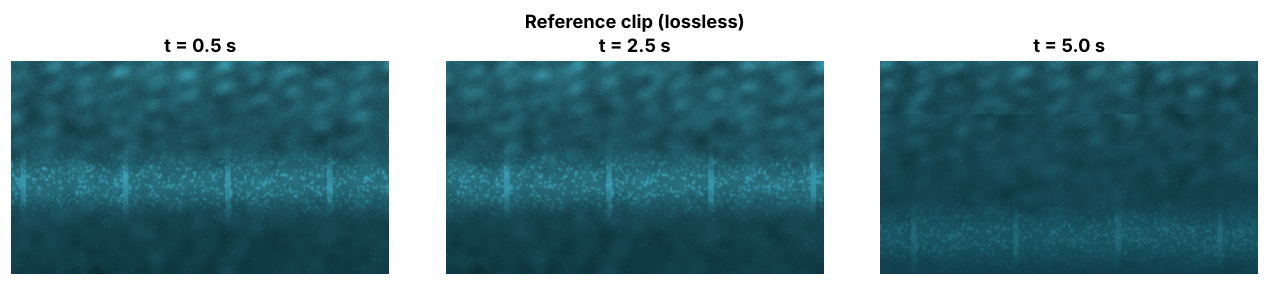

In [2]:
ROV_SOURCE = os.environ.get("ROV_SOURCE")   # e.g. "my_dive.mp4" — leave None for the synthetic clip
W, H, FPS, SECONDS = 1280, 720, 30, 6
N_FRAMES = FPS * SECONDS
SRC = WORK / "source.mkv"

def synth_underwater_clip(path, w=W, h=H, fps=FPS, n=N_FRAMES, seed=7):
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(seed)
    pan = 3                                             # pixels per frame of camera pan
    tex_w = w + 1200
    # Seabed / pipeline texture: low-frequency "rock" + high-frequency detail
    lo = gaussian_filter(rng.standard_normal((h, tex_w)), 18); lo /= np.abs(lo).max()
    hi = gaussian_filter(rng.standard_normal((h, tex_w)), 1.5); hi /= np.abs(hi).max()
    tex = 0.55 + 0.25 * lo + 0.12 * hi
    yy = np.arange(h)[:, None]
    pipe = np.exp(-((yy - 0.58 * h) / (0.11 * h)) ** 2)                # a horizontal pipeline
    seams = (np.sin(np.arange(tex_w) / 55.0) > 0.985).astype(float)    # weld seams
    tex = tex * (1 - 0.6 * pipe) + pipe * (0.75 + 0.15 * hi + 0.4 * seams[None, :])
    growth = gaussian_filter((rng.random((h, tex_w)) > 0.996).astype(float), 3) * 25
    tex = np.clip(tex + growth * pipe, 0, 1.4)
    depth = np.linspace(0, 1, h)[:, None]
    water = np.array([18, 92, 110]) / 255.0                            # blue-green water colour
    tint = np.array([0.35, 0.85, 0.95])                                # red absorbed first
    xs = np.arange(w)[None, :]
    p_n = 350; px = rng.uniform(0, w, p_n); py = rng.uniform(0, h, p_n)
    vx = rng.normal(0.4, 0.5, p_n); vy = rng.normal(-0.6, 0.4, p_n)
    cmd = [FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24",
           "-s", f"{w}x{h}", "-r", str(fps), "-i", "-", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(path)]
    proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    for i in range(n):
        t = i / fps
        if i < int(0.66 * n):                                          # camera 1: pan along the pipe
            view = tex[:, i * pan:i * pan + w]; turb = 0.35
        else:                                                          # camera 2: closer, darker view
            off = 600 + (i - int(0.66 * n)) * 2
            view = np.roll(tex[:, off:off + w], h // 4, axis=0) * 0.85; turb = 0.5
        caustic = (np.sin(xs / 37.0 + 2.1 * t) * np.sin(yy / 23.0 - 1.7 * t + xs / 90.0)) ** 2
        light = 0.75 + 0.35 * caustic * np.exp(-3 * depth)
        lum = view * light * (1.05 - 0.55 * depth)
        rgb = lum[..., None] * tint[None, None, :]
        haze = turb * (0.4 + 0.6 * depth)[..., None]                   # turbidity: fade to water colour
        rgb = rgb * (1 - haze) + water[None, None, :] * haze
        px += vx; py += vy; px %= w; py %= h                           # marine snow
        ix, iy = px.astype(int), py.astype(int)
        for dx, dy, a in ((0, 0, 0.5), (1, 0, 0.25), (0, 1, 0.25)):
            np.add.at(rgb, ((iy + dy) % h, (ix + dx) % w), a)
        rgb += rng.normal(0, 0.004, rgb.shape)                         # sensor noise (camera gain)
        proc.stdin.write((np.clip(rgb, 0, 1) * 255).astype(np.uint8).tobytes())
    proc.stdin.close(); proc.wait()

if not SRC.exists():
    if ROV_SOURCE:
        run([FFMPEG, "-y", "-hide_banner", "-i", ROV_SOURCE, "-t", str(SECONDS), "-vf",
             f"scale={W}:{H}:force_original_aspect_ratio=decrease,pad={W}:{H}:(ow-iw)/2:(oh-ih)/2,fps={FPS}",
             "-an", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(SRC)])
    else:
        t0 = time.time(); tmp = WORK / "source_tmp.mkv"; synth_underwater_clip(tmp); tmp.rename(SRC)
        print(f"Synthetic clip generated in {time.time()-t0:.1f} s")

# Encoders read an uncompressed copy, so CPU measurements contain (almost) only encoding work.
SRC_RAW = WORK / "source.yuv"
if not SRC_RAW.exists():
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(SRC), "-f", "rawvideo", "-pix_fmt", "yuv420p", str(SRC_RAW)])
SRC_IN = ["-f", "rawvideo", "-pix_fmt", "yuv420p", "-s", f"{W}x{H}", "-r", str(FPS), "-i", str(SRC_RAW)]
info = probe(SRC); print(info)
# Show three frames from the clip
fig, axs = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, t in zip(axs, (0.5, 2.5, 5.0)):
    png = WORK / f"src_{t}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(SRC), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(f"t = {t} s"); ax.axis("off")
plt.suptitle("Reference clip (lossless)", fontweight="bold"); plt.tight_layout(); plt.show()

<div align="center">

### 0.2 Interactive tuning panels

</div>


Experiments 3, 4, 5, 7 and 8 end with a red **Try it yourself** panel. Move the controls, press **Encode**, and the panel re-encodes the reference clip with *your* settings. It then shows the measured result next to the experiment's baseline.

* Results are cached in `work/`, so returning to a setting you already tried is instant.
* Panels need `ipywidgets` (included in `requirements.txt`). Without it they show the default setting only.
* Want more knobs, other codecs or your own footage? The stand-alone **ROV Encoding Lab** app (`encoding_lab/`) is the big brother of these panels.

In [3]:
import hashlib
from IPython.display import HTML, display

try:
    import ipywidgets as wdg
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

# Centre figures and tables when this notebook runs live in Jupyter (purely cosmetic).
display(HTML("<style>.jp-OutputArea-output img, .output_png img {display:block; margin:0 auto}"
             " .jp-RenderedHTMLCommon table {margin-left:auto; margin-right:auto}</style>"))

MIA_RED = "#C00000"
BATCH = os.environ.get("NB_BATCH") == "1"   # set by the build script that executes this notebook unattended

def cards(items):
    """Centred row of metric cards. items: (label, value, note) or (label, value, note, good) with good ∈ {True, False, None}."""
    html = []
    for it in items:
        label, value, note = it[:3]; good = it[3] if len(it) > 3 else None
        colour = {True: "#2e7d32", False: "#c62828", None: "#8a8a8a"}[good]
        html.append(f'<div style="min-width:120px; padding:10px 14px; margin:5px; border-radius:12px; background:#ffffff; '
                    f'border:1px solid #e4e4e4; box-shadow:0 1px 6px rgba(0,0,0,.06); text-align:center; display:inline-block">'
                    f'<div style="font-size:10.5px; letter-spacing:.08em; text-transform:uppercase; color:#8a8a8a">{label}</div>'
                    f'<div style="font-size:21px; font-weight:700; color:#262626; margin-top:2px">{value}</div>'
                    f'<div style="font-size:11px; color:{colour}">{note or "&nbsp;"}</div></div>')
    display(HTML(f'<div style="text-align:center">{"".join(html)}</div>'))

def delta(cur, ref, fmt, higher_is_better):
    """Text + colour flag for a change against a baseline."""
    d = cur - ref
    if abs(d) < 1e-9:
        return "same as baseline", None
    return f"{fmt(d)} vs baseline", (d > 0) == higher_is_better

def encode_cached(args, tag, vf=None, ext="mp4"):
    """Encode the reference clip with x264/FFmpeg arguments `args`, measure it, and cache the result in work/."""
    key = hashlib.sha1(json.dumps([args, vf, ext]).encode()).hexdigest()[:12]
    out = WORK / f"tune_{tag}_{key}.{ext}"; meta = out.with_suffix(".json")
    if out.exists() and meta.exists():
        return {**json.loads(meta.read_text()), "file": out}
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *(["-vf", vf] if vf else []), *args,
             "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim, pf = quality(out, SRC, per_frame=True)
    res = {"bitrate": p["bitrate_mbps"], "size": p["size_bytes"], "wall": r["wall_s"], "cpu": r["cpu_s"],
           "psnr": psnr, "ssim": ssim, "pf": [float(x) for x in pf]}
    meta.write_text(json.dumps(res))
    return {**res, "file": out}

def frame_png(path, t, tag):
    png = WORK / f"view_{tag}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(path), "-frames:v", "1", str(png)])
    return plt.imread(png)

PANELS = {}

def tuning_panel(name, title, subtitle, spec, render, live=False):
    """Build a centred control panel.

    spec:   {arg: (kind, options, default, label)}; kind ∈ int | float | options | toggle | check
            int/float options = (min, max, step); options/toggle options = list of values.
    render: function(**values) that prints cards and draws charts for one setting.
    live:   re-render on every change (for cheap calculations) instead of waiting for the Encode button.
    """
    header = (f'<div style="text-align:center; background-color:{MIA_RED}; color:#ffffff; border-radius:14px; '
              f'padding:12px 14px; margin:8px 0">'
              f'<div style="font-size:10px; letter-spacing:.3em; color:#ffd0d0">TRY IT YOURSELF</div>'
              f'<div style="font-size:18px; font-weight:700; margin-top:2px">{title}</div>'
              f'<div style="font-size:12.5px; color:#ffe6e6; margin-top:2px">{subtitle}</div></div>')
    defaults = {k: s[2] for k, s in spec.items()}
    if not HAS_WIDGETS:
        display(HTML(header)); print("ipywidgets is not installed: showing the default setting only.")
        render(**defaults); return
    ws, style = {}, {"description_width": "initial"}
    for k, (kind, opts, default, label) in spec.items():
        lay = wdg.Layout(width="310px")
        if kind == "int":
            ws[k] = wdg.IntSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "float":
            ws[k] = wdg.FloatSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "options":
            ws[k] = wdg.SelectionSlider(options=opts, value=default, description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "toggle":
            ws[k] = wdg.ToggleButtons(options=opts, value=default, description=label, style={**style, "button_width": "auto"})
        elif kind == "check":
            ws[k] = wdg.Checkbox(value=default, description=label, style=style, indent=False, layout=wdg.Layout(width="310px"))
    out = wdg.Output(layout=wdg.Layout(width="100%"))
    status = wdg.HTML()
    button = wdg.Button(description="Encode", icon="play", button_style="danger", layout=wdg.Layout(width="160px"))

    def refresh(*_):
        t0 = time.perf_counter(); status.value = "<i>working…</i>"; button.disabled = True
        with out:
            out.clear_output(wait=True)
            try:
                render(**{k: w.value for k, w in ws.items()})
                status.value = f'<span style="color:#8a8a8a">updated in {time.perf_counter() - t0:.1f} s</span>'
            except Exception as exc:   # show the problem in the panel instead of killing the widget
                print(f"This setting failed: {exc}"); status.value = '<span style="color:#c62828">failed</span>'
        button.disabled = False

    toggles = [w for w in ws.values() if isinstance(w, wdg.ToggleButtons)]
    others = [w for w in ws.values() if not isinstance(w, wdg.ToggleButtons)]
    grid = wdg.GridBox(others, layout=wdg.Layout(grid_template_columns="repeat(3, 320px)", justify_content="center", grid_gap="4px 10px"))
    rows = [wdg.HTML(header), *[wdg.HBox([t], layout=wdg.Layout(justify_content="center")) for t in toggles], grid]
    if live:
        for w in ws.values():
            w.observe(refresh, names="value")
        rows.append(wdg.HBox([status], layout=wdg.Layout(justify_content="center")))
    else:
        button.on_click(refresh)
        rows.append(wdg.HBox([button, status], layout=wdg.Layout(justify_content="center", align_items="center", grid_gap="12px")))
    rows.append(out)
    box = wdg.VBox(rows, layout=wdg.Layout(border="1px solid #eeeeee", padding="0 8px 10px", width="100%"))
    PANELS[name] = {"widgets": ws, "button": button, "refresh": refresh, "out": out}
    display(box)
    if BATCH:   # unattended run (e.g. nbclient): draw the default result straight into the cell
        status.value = '<span style="color:#8a8a8a">showing the default setting: run this cell to use the controls</span>'
        render(**defaults)
    else:
        refresh()
print("Tuning panels ready" + ("" if HAS_WIDGETS else " (static mode: pip install ipywidgets for the controls)"))

Tuning panels ready


<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 1</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">How big is raw video?</h2>
</div>


**Question.** If a camera sent every pixel without compression, how much bandwidth would it need?

**Theory.** A video is a sequence of images. Each image has $W \times H$ pixels, each pixel needs some number of **bits per pixel** (bpp), and we send $f$ images per second:

$$
R_{\text{raw}} \;=\; W \times H \times \text{bpp} \times f \qquad [\text{bit/s}]
$$

<div align="center">

| Symbol | Meaning | Example |
|---|---|---|
| $W \times H$ | resolution (pixels per frame) | 1920 × 1080 = 2 073 600 px |
| bpp | bits per pixel — depends on the **pixel format** | RGB24 = 24, YUYV 4:2:2 = 16, NV12 4:2:0 = 12 |
| $f$ | frame rate (frames per second) | 30 |

</div>


**Worked example — 1080p30 in RGB24:** $1920 \times 1080 \times 24 \times 30 = 1\,492\,992\,000$ bit/s ≈ **1.49 Gbit/s**. That is *one camera*, already **more than a whole Gigabit Ethernet link**.

Why the pixel formats differ: the eye is much more sensitive to brightness (luma, **Y**) than to colour (chroma, **U/V**). **4:2:0** keeps full-resolution luma but stores one U and one V sample for every 2×2 block of pixels, so each pixel costs $8 + \tfrac{8+8}{4} = 12$ bits instead of 24. We will come back to this in the slides.

> Units: in networking, **1 Mbit/s = 10⁶ bit/s** (decimal). Storage often uses MiB = 2²⁰ bytes. We use decimal bits everywhere in this notebook, and write **Mb/s** for megabits per second and **MB** for megabytes.

In [4]:
PIXEL_FORMATS = {"RGB24 (8-bit RGB)": 24, "YUYV 4:2:2 (USB webcam raw)": 16, "NV12 / YUV420P 4:2:0": 12}
RESOLUTIONS = {"640×480": (640, 480), "1280×720": (1280, 720), "1920×1080": (1920, 1080), "3840×2160": (3840, 2160)}

def raw_mbps(w, h, fps, bpp):
    return w * h * bpp * fps / 1e6

rows = []
for rname, (w, h) in RESOLUTIONS.items():
    for fps in (15, 30, 60):
        row = {"resolution": rname, "fps": fps}
        for pname, bpp in PIXEL_FORMATS.items():
            row[pname] = raw_mbps(w, h, fps, bpp)
        rows.append(row)
raw_table = pd.DataFrame(rows)
print("Raw bandwidth of ONE camera, Mb/s")
display(raw_table.style.format({c: "{:,.0f}" for c in PIXEL_FORMATS}).hide(axis="index"))

one = raw_mbps(1920, 1080, 30, 24); eight = 8 * one
print(f"1 × 1080p30 RGB24 = {one:,.0f} Mb/s   |   8 cameras = {eight:,.0f} Mb/s = {eight/1000:.1f} Gb/s")
print(f"1 × 1080p30 NV12  = {raw_mbps(1920,1080,30,12):,.0f} Mb/s   |   8 cameras = {8*raw_mbps(1920,1080,30,12):,.0f} Mb/s")

Raw bandwidth of ONE camera, Mb/s


resolution,fps,RGB24 (8-bit RGB),YUYV 4:2:2 (USB webcam raw),NV12 / YUV420P 4:2:0
640×480,15,111,74,55
640×480,30,221,147,111
640×480,60,442,295,221
1280×720,15,332,221,166
1280×720,30,664,442,332
1280×720,60,"1,327",885,664
1920×1080,15,746,498,373
1920×1080,30,"1,493",995,746
1920×1080,60,"2,986","1,991","1,493"
3840×2160,15,"2,986","1,991","1,493"


1 × 1080p30 RGB24 = 1,493 Mb/s   |   8 cameras = 11,944 Mb/s = 11.9 Gb/s
1 × 1080p30 NV12  = 746 Mb/s   |   8 cameras = 5,972 Mb/s


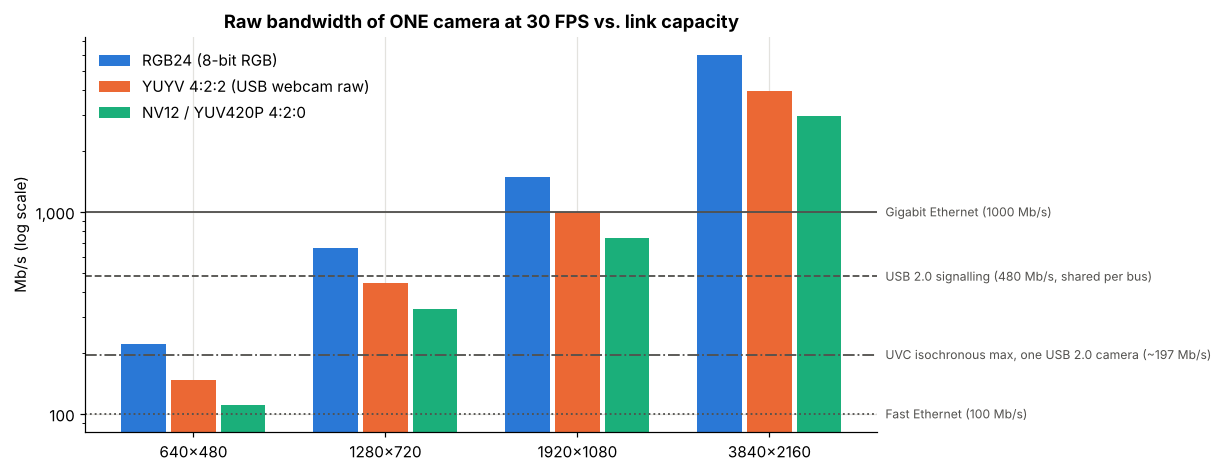

In [5]:
# Chart: one camera's raw bandwidth at 30 FPS vs the capacity of the links an ROV actually has.
LINKS = {"Fast Ethernet (100 Mb/s)": 100, "UVC isochronous max, one USB 2.0 camera (~197 Mb/s)": 196.6,
         "USB 2.0 signalling (480 Mb/s, shared per bus)": 480, "Gigabit Ethernet (1000 Mb/s)": 1000}
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(RESOLUTIONS)); width = 0.26
for k, (pname, bpp) in enumerate(PIXEL_FORMATS.items()):
    vals = [raw_mbps(w, h, 30, bpp) for (w, h) in RESOLUTIONS.values()]
    ax.bar(x + (k - 1) * width, vals, width - 0.03, label=pname, color=PALETTE[k])
for (lname, cap), ls in zip(LINKS.items(), (":", "-.", "--", "-")):
    ax.axhline(cap, color="#52514e", ls=ls, lw=1.2)
    ax.text(1.01, cap, lname, fontsize=8, color="#52514e", ha="left", va="center", transform=ax.get_yaxis_transform())
ax.set_yscale("log"); ax.yaxis.set_major_formatter(FuncFormatter(mbps_fmt))
ax.set_xticks(x, RESOLUTIONS.keys()); ax.set_ylabel("Mb/s (log scale)")
ax.set_title("Raw bandwidth of ONE camera at 30 FPS vs. link capacity"); ax.legend(loc="upper left")
fig.subplots_adjust(left=0.08, right=0.68, bottom=0.12, top=0.9); plt.show()

**Interpretation.**

* Raw 1080p30 from even **one** camera does not fit a Fast-Ethernet tether, and 8 raw 1080p cameras would need ~6–12 Gb/s. **Compression is not optional; it is the core of the system.**
* Look at the USB lines. A USB 2.0 UVC camera sending *uncompressed* YUYV can only do about 640×480@30 or 1280×720@~10. That is why most USB webcams switch to **MJPEG** (compressed inside the camera) at 720p and above — and why many student ROVs end up streaming MJPEG without ever deciding to.
* USB 2.0 bandwidth is **shared by every device on the same bus** (a hub does not add bandwidth). High-speed USB also limits *periodic* (isochronous) traffic to 80 % of each micro-frame, and many UVC cameras *reserve* a large isochronous slot even when sending small MJPEG frames. The classic symptom with 3–4 USB cameras on one hub is that the next camera fails to open (`No space left on device` / `VIDIOC_STREAMON` errors). **Before blaming the network, check `lsusb -t`.**

<div align="center">

### Exercises

</div>

1. Your team's camera outputs YUYV 640×480 at 30 FPS. How many such cameras fit on one USB 2.0 bus (use 80 % of 480 Mb/s as the periodic budget)?
2. A 100 Mb/s tether must carry 8 cameras. What is the **maximum average bitrate per camera** if you keep 30 % headroom? (Answer: $100 \times 0.7 / 8 = 8.75$ Mb/s *before* protocol overhead.)
3. Why is "lower the resolution" a weak first response to a bandwidth problem? *(Hint: compare the ratio raw/compressed in Experiment 2.)*

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 2</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Your first encodes: H.264, H.265, MJPEG, AV1</h2>
</div>


**Question.** How much smaller does the same 6-second clip become with different codecs, and what does it cost in encoding time?

**Theory (short).**

<div align="center">

| Codec | Idea | Uses previous frames? |
|---|---|---|
| **MJPEG** | Every frame is an independent JPEG image | ❌ intra-only |
| **H.264 / AVC** | Predicts each block from neighbours *or* from previous frames, codes only the difference | ✅ |
| **H.265 / HEVC** | Same idea, bigger and more flexible blocks (CTUs up to 64×64), better prediction tools | ✅ |
| **AV1** | Royalty-free successor to VP9, even more tools; expensive to encode in software | ✅ |

</div>


**The commands, line by line** (the H.264 one):

```bash
ffmpeg -y -i work/source.mkv \      # -y overwrite; -i input file
       -c:v libx264 \               # video codec = the x264 software H.264 encoder
       -preset medium \             # speed/efficiency trade-off (Experiment 4)
       -crf 23 \                    # constant-quality target: lower = better quality, bigger file (Experiment 3)
       -pix_fmt yuv420p \           # 4:2:0 chroma — what every hardware decoder and browser supports
       -an \                        # no audio
       work/e2_h264.mp4             # MP4 container
```

* `libx265` uses `-crf 28` as its default "visually similar" point — **CRF numbers are not comparable between codecs.**
* MJPEG uses `-q:v` (2 = best, 31 = worst) instead of CRF.
* `libsvtav1 -preset 8` is a fast SVT-AV1 setting; AV1 CRF runs from 0 to 63.

We also record **PSNR** and **SSIM** (explained properly in Experiment 6) so we are not comparing file sizes blindly.

Raw 4:2:0 size of the clip: 249 MB  (332 Mb/s)


codec,size_MB,bitrate_Mb/s,compression_ratio,encode_fps,cores_used,PSNR_dB,SSIM
"H.264 (x264, CRF 23)",1.13,1.50,221:1,39,1.8,46.4,0.9818
"H.265 (x265, CRF 28)",0.42,0.56,595:1,34,1.9,40.4,0.9613
MJPEG (q:v 5),6.15,8.20,40:1,270,1.5,45.5,0.9785
"AV1 (SVT-AV1, CRF 35)",0.55,0.74,449:1,23,1.9,43.4,0.9771


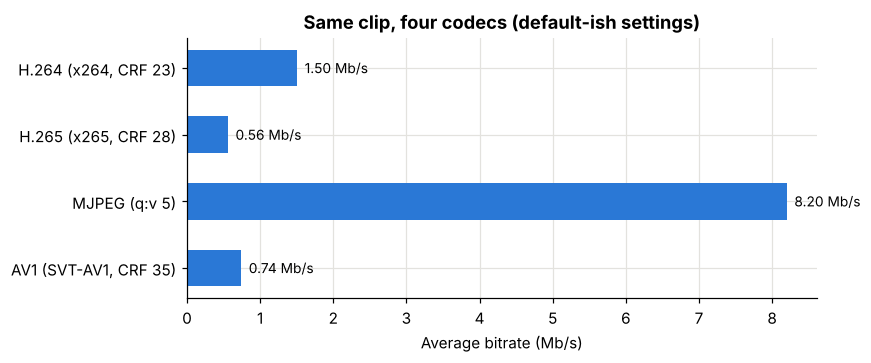

In [6]:
E2 = [
    ("H.264 (x264, CRF 23)",  "libx264",   ["-c:v", "libx264", "-preset", "medium", "-crf", "23", "-pix_fmt", "yuv420p"], "mp4"),
    ("H.265 (x265, CRF 28)",  "libx265",   ["-c:v", "libx265", "-preset", "medium", "-crf", "28", "-pix_fmt", "yuv420p",
                                             "-tag:v", "hvc1", "-x265-params", "log-level=error"], "mp4"),
    ("MJPEG (q:v 5)",         "mjpeg",     ["-c:v", "mjpeg", "-q:v", "5", "-pix_fmt", "yuvj420p"], "mkv"),
    ("AV1 (SVT-AV1, CRF 35)", "libsvtav1", ["-c:v", "libsvtav1", "-preset", "8", "-crf", "35", "-pix_fmt", "yuv420p"], "mkv"),
]
raw_bits = W * H * 12 * N_FRAMES   # 4:2:0 raw size of the clip, in bits
rows = []
for label, enc, args, ext in E2:
    if not HAS.get(enc):
        print(f"skip {label}: encoder {enc} not available in this FFmpeg build"); continue
    out = WORK / f"e2_{enc}.{ext}"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *args, "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"codec": label, "size_MB": p["size_bytes"] / 1e6, "bitrate_Mb/s": p["bitrate_mbps"],
                 "compression_ratio": raw_bits / (p["size_bytes"] * 8), "encode_fps": N_FRAMES / r["wall_s"],
                 "cores_used": r["cpu_s"] / r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim})
e2 = pd.DataFrame(rows)
print(f"Raw 4:2:0 size of the clip: {raw_bits/8/1e6:.0f} MB  ({raw_mbps(W,H,FPS,12):.0f} Mb/s)")
display(e2.style.format({"size_MB": "{:.2f}", "bitrate_Mb/s": "{:.2f}", "compression_ratio": "{:,.0f}:1",
                         "encode_fps": "{:.0f}", "cores_used": "{:.1f}", "PSNR_dB": "{:.1f}", "SSIM": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(e2["codec"], e2["bitrate_Mb/s"], color=PALETTE[0], height=0.55)
for y, v in enumerate(e2["bitrate_Mb/s"]):
    ax.text(v, y, f"  {v:.2f} Mb/s", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Average bitrate (Mb/s)"); ax.set_title("Same clip, four codecs (default-ish settings)")
plt.tight_layout(); plt.show()

**Interpretation.**

* Even at default settings, the inter-frame codecs (H.264/H.265/AV1) are typically **several times smaller than MJPEG**, and **one to two orders of magnitude smaller than raw**. On a bandwidth-limited tether, *switching codec is usually worth far more than lowering resolution.*
* But look at the PSNR/SSIM columns before declaring a winner: the four encodes are **not at equal quality**. A fair comparison draws a whole *rate–quality curve* for each codec — we do that in Experiment 6.
* Look at **encode_fps** and **cores_used**. H.265 and AV1 buy their efficiency with CPU time. On a Raspberry Pi 5 (no hardware encoder) that CPU budget is the real constraint; on a Jetson Nano, the hardware encoder makes H.264/H.265 almost free for the CPU. → Experiment 10.
* MJPEG's one big advantage: every frame stands alone, so decoding is trivial, latency is minimal, and a lost frame never corrupts the next one.

<div align="center">

### Exercises

</div>

1. Run `ffprobe -hide_banner work/e2_libx264.mp4` and identify: container, codec, profile, pixel format, resolution, frame rate, bitrate.
2. Re-encode MJPEG at `-q:v 2` and `-q:v 15`. How far does the bitrate move? Is MJPEG at `-q:v 15` still usable for piloting?
3. Which of these codecs can **your pilot's browser** decode? (Search "caniuse H.265" and test on the actual topside laptop.)

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 3</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Quality-based (CRF) vs bitrate-based encoding</h2>
</div>


**Question.** Should we tell the encoder *"give me this quality"* or *"give me this bitrate"*?

**Theory.**

* **CRF (Constant Rate Factor)** — *quality-based*. The encoder chooses a quantizer per frame so that perceived quality stays roughly constant. Easy scenes get few bits, complex scenes many. **Bitrate varies with content.** Each +6 CRF roughly halves the bitrate in x264.
* **Target bitrate with a VBV buffer** — *bitrate-based*. We specify `-b:v` (average), `-maxrate` (ceiling) and `-bufsize` (how much burst is tolerated). **Quality varies with content.** This is what live streaming over a fixed-capacity link needs.

$$
\text{bufsize} \approx \text{maxrate} \times \text{(tolerated burst time)} \qquad\Rightarrow\qquad \text{small bufsize} = \text{smoother bitrate} + \text{lower latency} - \text{lower quality on hard frames}
$$

> On an ROV, a tether has a hard capacity. A CRF stream can suddenly double its bitrate when the ROV stirs up sediment — exactly when the pilot needs the video most. This is why live systems use **capped** rate control (VBV / CBR), and use CRF mainly for **recording**.

In [7]:
CRFS = [18, 23, 28, 33, 38, 43]
TARGETS_MBPS = [0.25, 0.5, 1, 2, 4, 8]
rows = []
for crf in CRFS:
    out = WORK / f"e3_crf{crf}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-crf", str(crf), "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "CRF", "setting": f"crf {crf}", "bitrate_Mb/s": p["bitrate_mbps"], "size_MB": p["size_bytes"]/1e6,
                 "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
for tgt in TARGETS_MBPS:
    out = WORK / f"e3_vbv{tgt}.mp4"; kb = int(tgt * 1000)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-b:v", f"{kb}k", "-maxrate", f"{kb}k", "-bufsize", f"{kb // 2}k",   # 0.5 s of buffer
             "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "Target bitrate (VBV)", "setting": f"{tgt} Mb/s", "bitrate_Mb/s": p["bitrate_mbps"],
                 "size_MB": p["size_bytes"]/1e6, "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e3 = pd.DataFrame(rows)
display(e3.drop(columns="file").style.format({"bitrate_Mb/s": "{:.2f}", "size_MB": "{:.2f}", "encode_s": "{:.1f}",
                                              "PSNR_dB": "{:.1f}", "SSIM": "{:.4f}"}).hide(axis="index"))

mode,setting,bitrate_Mb/s,size_MB,encode_s,PSNR_dB,SSIM
CRF,crf 18,2.49,1.87,5.4,48.1,0.9867
CRF,crf 23,1.50,1.13,4.4,46.4,0.9818
CRF,crf 28,0.93,0.70,3.6,44.0,0.9729
CRF,crf 33,0.51,0.38,3.4,40.9,0.9597
CRF,crf 38,0.16,0.12,2.4,38.2,0.9426
CRF,crf 43,0.08,0.06,2.2,36.6,0.9300
Target bitrate (VBV),0.25 Mb/s,0.17,0.13,2.8,38.1,0.9407
Target bitrate (VBV),0.5 Mb/s,0.40,0.30,3.4,40.0,0.9547
Target bitrate (VBV),1 Mb/s,0.78,0.59,3.6,42.9,0.9686
Target bitrate (VBV),2 Mb/s,1.50,1.12,4.4,46.2,0.9813


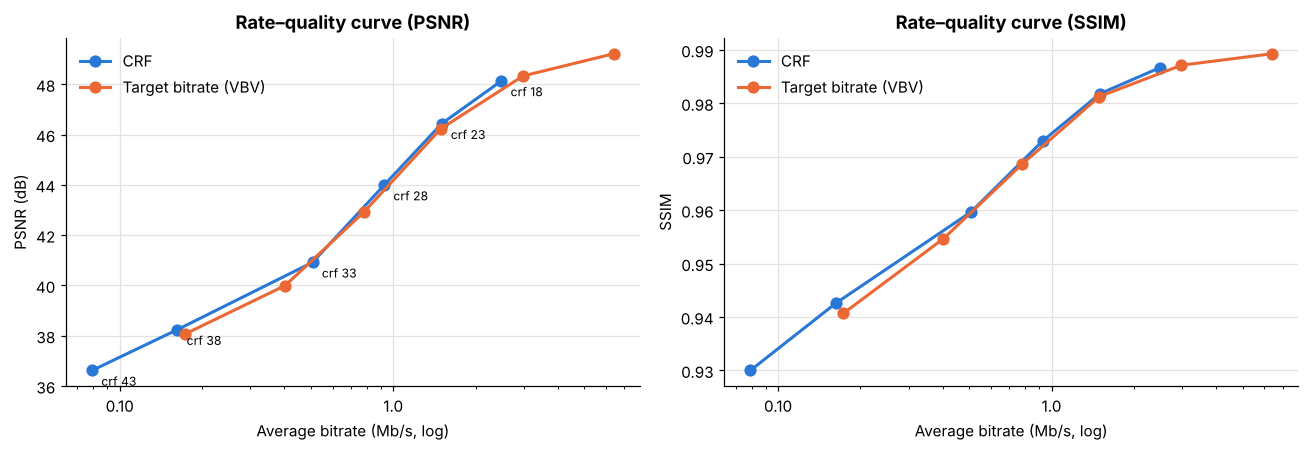

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (mode, g) in enumerate(e3.groupby("mode", sort=False)):
    axs[0].plot(g["bitrate_Mb/s"], g["PSNR_dB"], "o-", label=mode, color=PALETTE[k])
    axs[1].plot(g["bitrate_Mb/s"], g["SSIM"], "o-", label=mode, color=PALETTE[k])
for _, r in e3[e3["mode"] == "CRF"].iterrows():
    axs[0].annotate(r["setting"], (r["bitrate_Mb/s"], r["PSNR_dB"]), textcoords="offset points", xytext=(6, -10), fontsize=8)
for ax, yl in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt))
    ax.set_xlabel("Average bitrate (Mb/s, log)"); ax.set_ylabel(yl); ax.legend()
axs[0].set_title("Rate–quality curve (PSNR)"); axs[1].set_title("Rate–quality curve (SSIM)")
plt.tight_layout(); plt.show()

Now the important part for live streaming: **how does the bitrate behave over time?** We match a VBV encode to the *same average bitrate* as CRF 23 and plot the bitrate in 200 ms windows. Remember the scene cut at t = 4 s.

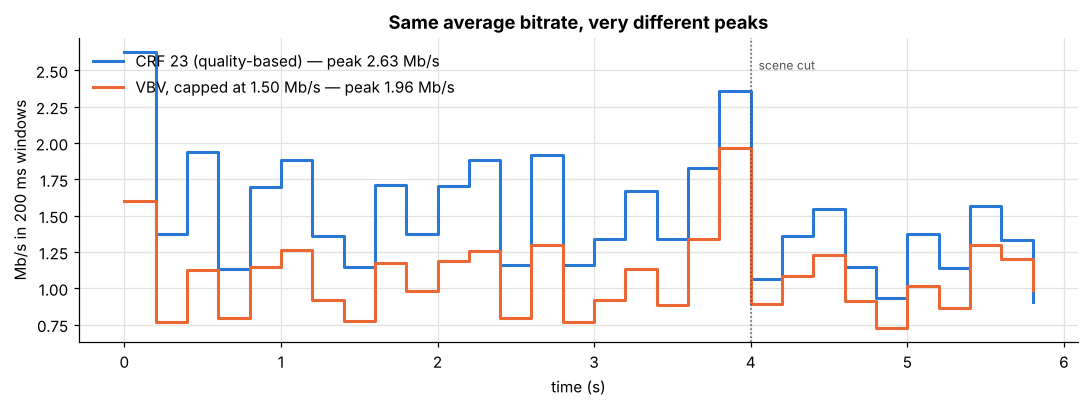

In [9]:
crf23 = e3[(e3["mode"] == "CRF") & (e3["setting"] == "crf 23")].iloc[0]
avg_kb = int(crf23["bitrate_Mb/s"] * 1000)
vbv_match = WORK / "e3_vbv_match.mp4"
run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
     "-b:v", f"{avg_kb}k", "-maxrate", f"{avg_kb}k", "-bufsize", f"{avg_kb // 3}k", "-pix_fmt", "yuv420p", "-an", str(vbv_match)])

def windowed_mbps(path, win=0.2):
    pk = packets(path); bins = np.floor(pk["pts"] / win)
    s = pk.groupby(bins)["size"].sum() * 8 / win / 1e6
    return s.index.values * win, s.values, pk

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (label, path) in enumerate((("CRF 23 (quality-based)", crf23["file"]), (f"VBV, capped at {avg_kb/1000:.2f} Mb/s", vbv_match))):
    t, mb, pk = windowed_mbps(path)
    ax.step(t, mb, where="post", label=f"{label} — peak {mb.max():.2f} Mb/s", color=PALETTE[k])
ax.axvline(4.0, color="#52514e", ls=":", lw=1); ax.text(4.05, ax.get_ylim()[1]*0.92, "scene cut", fontsize=8, color="#52514e")
ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s in 200 ms windows"); ax.set_title("Same average bitrate, very different peaks")
ax.legend(); plt.tight_layout(); plt.show()

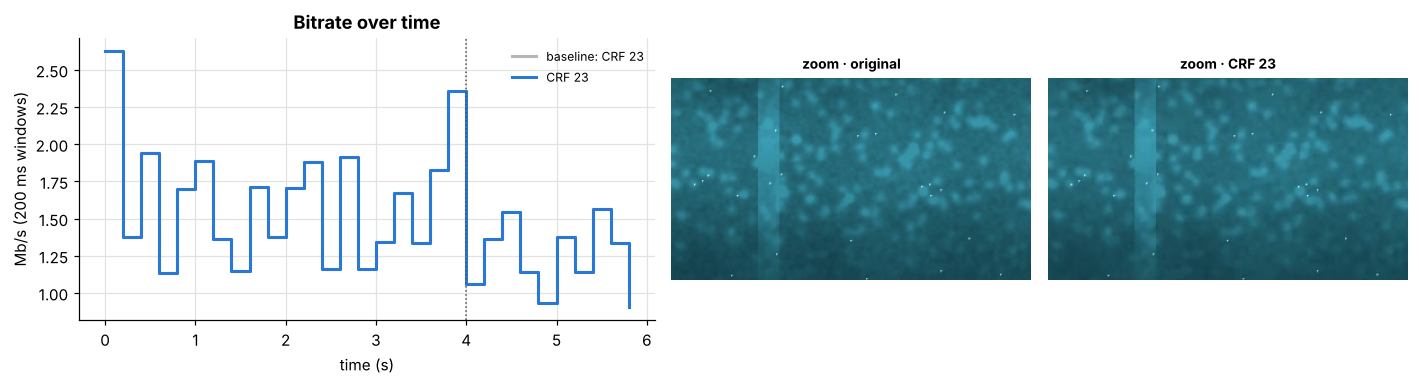

In [10]:
def tune_rate(mode, crf, target, buffer_s):
    if mode == "CRF (quality)":
        args = ["-c:v", "libx264", "-preset", "medium", "-crf", str(crf)]; label = f"CRF {crf}"
    else:
        kb = int(target * 1000)
        args = ["-c:v", "libx264", "-preset", "medium", "-b:v", f"{kb}k", "-maxrate", f"{kb}k", "-bufsize", f"{int(kb * buffer_s)}k"]
        label = f"cap {target:g} Mb/s, buffer {buffer_s:g} s"
    res = encode_cached(args, "e3")
    t, mb, _ = windowed_mbps(res["file"]); t0, mb0, _ = windowed_mbps(crf23["file"])
    cards([("bitrate", f"{res['bitrate']:.2f} Mb/s", *delta(res["bitrate"], crf23["bitrate_Mb/s"], lambda d: f"{d:+.2f}", False)),
           ("peak (200 ms)", f"{mb.max():.2f} Mb/s", *delta(mb.max(), mb0.max(), lambda d: f"{d:+.2f}", False)),
           ("compression", f"{raw_bits / (res['size'] * 8):,.0f} : 1", "vs raw 4:2:0"),
           ("PSNR", f"{res['psnr']:.1f} dB", *delta(res["psnr"], crf23["PSNR_dB"], lambda d: f"{d:+.1f} dB", True)),
           ("SSIM", f"{res['ssim']:.4f}", *delta(res["ssim"], crf23["SSIM"], lambda d: f"{d:+.4f}", True))])
    fig = plt.figure(figsize=(13, 3.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1, 1])
    ax = fig.add_subplot(gs[0])
    ax.step(t0, mb0, where="post", color="#b5b5b5", label="baseline: CRF 23")
    ax.step(t, mb, where="post", color=PALETTE[0], label=label)
    ax.axvline(4.0, color="#52514e", ls=":", lw=1); ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s (200 ms windows)")
    ax.set_title("Bitrate over time"); ax.legend(fontsize=8)
    y0, x0 = int(0.48 * H), int(0.40 * W)   # zoom on the pipeline at t = 2 s, where detail is hardest to keep
    for k, (img, cap) in enumerate(((frame_png(SRC, 2.0, "e3_ref"), "original"), (frame_png(res["file"], 2.0, "e3_enc"), label))):
        a = fig.add_subplot(gs[k + 1]); a.imshow(img[y0:y0 + H // 4, x0:x0 + W // 4]); a.set_title(f"zoom · {cap}", fontsize=9); a.axis("off")
    plt.tight_layout(); plt.show()

tuning_panel("e3", "Rate control", "Quality target or bitrate cap: watch the peaks and the detail",
             {"mode": ("toggle", ["CRF (quality)", "Target bitrate (VBV)"], "CRF (quality)", ""),
              "crf": ("int", (12, 45, 1), 23, "CRF"),
              "target": ("options", [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0], 1.0, "bitrate cap (Mb/s)"),
              "buffer_s": ("options", [0.1, 0.25, 0.5, 1.0, 2.0], 0.5, "VBV buffer (s)")}, tune_rate)

**Interpretation.**

* The rate–quality curve has **diminishing returns**: the step from 0.5 → 1 Mb/s buys far more quality than 4 → 8 Mb/s. Somewhere on that curve is the "good enough for piloting" point — find it *with your footage and your pilots*, not by guessing.
* With CRF, the **peaks** (I-frames, scene cuts, sudden motion, sediment clouds) can be several times the average. A tether planned on *average* bitrate will congest on *peaks* → packet loss → corrupted video exactly when things get exciting.
* VBV trades those peaks for temporary quality drops. That is usually the right trade for a live link; record a CRF stream locally (on the ROV or topside) if you need high quality for later analysis.

<div align="center">

### Exercises

</div>

1. From the CRF table, estimate the "half-bitrate CRF step" for x264 on this clip. Is it close to 6?
2. Repeat the VBV encode with `-bufsize` equal to 2× the bitrate. What happens to the peaks? What would that do to latency?
3. Which mode would you use for (a) the pilot's live view, (b) the recording used for a mission photomosaic or measurement task? Why?

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 4</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Encoder presets: speed vs efficiency</h2>
</div>


**Question.** x264 offers presets from `ultrafast` to `veryslow`. What do we gain and lose?

**Theory.** A preset bundles dozens of internal decisions: how hard to search for motion vectors (`me`, `subme`, `merange`), how many reference frames, how many B-frames, how many frames of **lookahead** to analyse, which block partitions to try, whether to use CABAC entropy coding, and so on. Slower presets search harder, so they find cheaper ways to describe the same picture → **fewer bits for the same quality** — at the price of CPU time.

We keep `-crf 23` constant and measure for each preset:

* **encode FPS** — can it keep up with 30 FPS live?
* **cores used** = CPU time / wall time — how much of the SBC it would eat.
* **bitrate and PSNR** — efficiency.

preset,encode_fps,cores_used,cpu_ms_per_frame,bitrate_Mb/s,PSNR_dB,SSIM
ultrafast,248,1.6,6.4,2.77,45.00,0.9749
superfast,142,1.8,12.3,2.31,46.65,0.9835
veryfast,100,1.8,18.0,1.24,45.24,0.9793
faster,52,1.8,34.4,1.44,46.30,0.9818
fast,50,1.7,35.2,1.50,46.38,0.9819
medium,39,1.7,43.6,1.50,46.43,0.9818
slow,28,1.7,60.8,1.36,46.33,0.9815
slower,14,1.8,122.8,1.31,46.34,0.9815
veryslow,9,1.8,211.0,1.17,46.36,0.9820


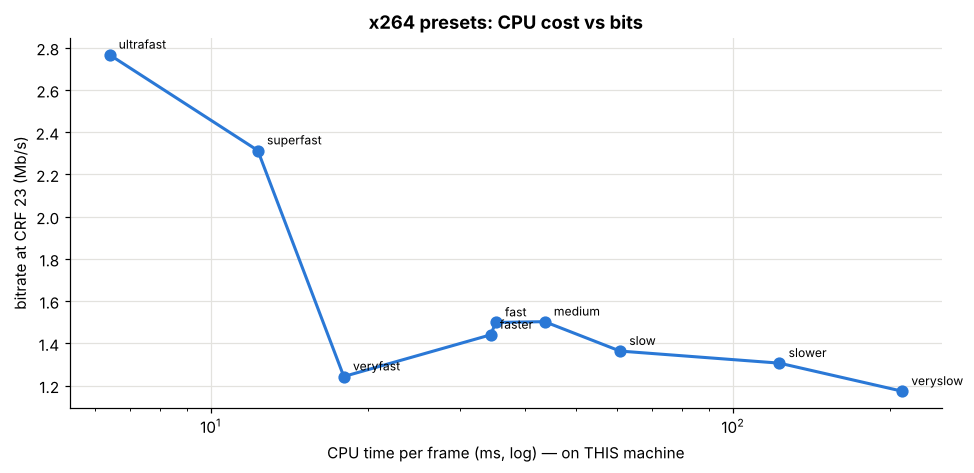

In [11]:
PRESETS = ["ultrafast", "superfast", "veryfast", "faster", "fast", "medium", "slow", "slower", "veryslow"]
rows = []
for pr in PRESETS:
    out = WORK / f"e4_{pr}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", pr,
             "-crf", "23", "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"preset": pr, "encode_fps": N_FRAMES / r["wall_s"], "cores_used": r["cpu_s"] / r["wall_s"],
                 "cpu_ms_per_frame": 1000 * r["cpu_s"] / N_FRAMES, "bitrate_Mb/s": p["bitrate_mbps"], "PSNR_dB": psnr, "SSIM": ssim})
e4 = pd.DataFrame(rows)
display(e4.style.format({"encode_fps": "{:.0f}", "cores_used": "{:.1f}", "cpu_ms_per_frame": "{:.1f}",
                         "bitrate_Mb/s": "{:.2f}", "PSNR_dB": "{:.2f}", "SSIM": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(e4["cpu_ms_per_frame"], e4["bitrate_Mb/s"], "o-", color=PALETTE[0])
for _, r in e4.iterrows():
    ax.annotate(r["preset"], (r["cpu_ms_per_frame"], r["bitrate_Mb/s"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("CPU time per frame (ms, log) — on THIS machine")
ax.set_ylabel("bitrate at CRF 23 (Mb/s)"); ax.set_title("x264 presets: CPU cost vs bits")
plt.tight_layout(); plt.show()

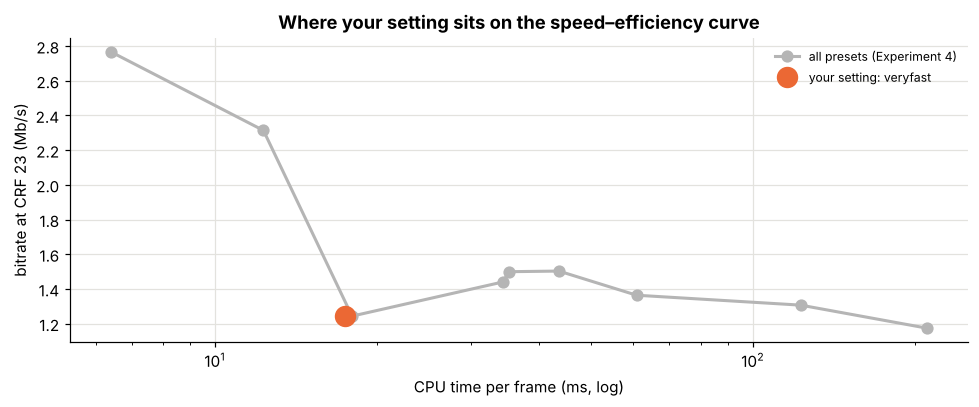

In [12]:
def tune_preset(preset, zerolatency):
    args = ["-c:v", "libx264", "-preset", preset, "-crf", "23", *(["-tune", "zerolatency"] if zerolatency else [])]
    res = encode_cached(args, "e4")
    base = e4[e4["preset"] == "medium"].iloc[0]
    fps_ = N_FRAMES / res["wall"]; cores = res["cpu"] / res["wall"]; ms = 1000 * res["cpu"] / N_FRAMES
    cards([("encode speed", f"{fps_:.0f} fps", f"{fps_ / FPS:.1f}× real time", fps_ >= FPS),
           ("CPU per frame", f"{ms:.1f} ms", *delta(ms, base["cpu_ms_per_frame"], lambda d: f"{d:+.1f} ms", False)),
           ("cores used", f"{cores:.1f}", f"of {CPU_CORES} on this machine"),
           ("bitrate", f"{res['bitrate']:.2f} Mb/s", *delta(res["bitrate"], base["bitrate_Mb/s"], lambda d: f"{d:+.2f}", False)),
           ("PSNR", f"{res['psnr']:.2f} dB", *delta(res["psnr"], base["PSNR_dB"], lambda d: f"{d:+.2f} dB", True))])
    need = ms * FPS * 8 / 1000
    display(HTML(f'<p style="text-align:center">Eight 720p30 cameras with these settings would need <b>{need:.1f} cores</b> '
                 f'of <i>this</i> computer. Repeat on the SBC before you believe it.</p>'))
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(e4["cpu_ms_per_frame"], e4["bitrate_Mb/s"], "o-", color="#b5b5b5", label="all presets (Experiment 4)")
    ax.plot([ms], [res["bitrate"]], "o", ms=13, color=PALETTE[1], label=f"your setting: {preset}{' + zerolatency' if zerolatency else ''}")
    ax.set_xscale("log"); ax.set_xlabel("CPU time per frame (ms, log)"); ax.set_ylabel("bitrate at CRF 23 (Mb/s)")
    ax.set_title("Where your setting sits on the speed–efficiency curve"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

tuning_panel("e4", "Encoder speed", "Same CRF, different preset: CPU cost versus bits",
             {"preset": ("options", PRESETS, "veryfast", "preset"),
              "zerolatency": ("check", None, False, "-tune zerolatency (no B-frames, no lookahead)")}, tune_preset)

**Interpretation.**

* Read the chart from left to right: each slower preset costs more CPU per frame; the bitrate saving shrinks fast after `medium`/`slow`. Note that CRF 23 is *not exactly* equal quality across presets (check the PSNR column) — `ultrafast` disables many tools, so its bitrate *and* quality both differ.
* For a live ROV encoder on an SBC **without** a hardware encoder, you will usually live at `ultrafast`–`veryfast` with `-tune zerolatency`. Raspberry Pi's own white paper measured 1080p30 at roughly 62–90 % of one Cortex-A76 core with an `ultrafast`/zerolatency configuration, and ~100–150 % of a core with a `superfast` high-quality configuration (see References).
* **CPU time per frame** is the number you can transfer between machines: measure it on the actual SBC, multiply by FPS × number of streams, and compare with the cores you can spare *after* the control software, telemetry and the web server.

<div align="center">

### Exercises

</div>

1. Using `cpu_ms_per_frame` for `ultrafast`, how many 720p30 streams could **this** machine encode if you reserve one core for everything else?
2. Repeat this experiment **on your SBC** (Raspberry Pi 5 or Jetson Nano). By what factor is it slower than your laptop?
3. Why might a *faster* preset produce *lower* latency even if the machine is fast enough for `medium`? *(Hint: lookahead and B-frames — Experiment 9.)*

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 5</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">GOP, keyframes, and what happens when packets are lost</h2>
</div>


**Question.** How often should the encoder send a full picture (I-frame), and why does it matter on a tether?

**Theory.**

* **I-frame (intra):** coded using only itself — like a JPEG. Big. A decoder can start here.
* **P-frame (predicted):** coded as *differences* from earlier frames, using motion vectors. Small.
* **B-frame (bi-predicted):** may also reference a *future* frame — so the encoder must wait for that future frame → **adds latency**. Live low-latency streams usually disable B-frames.
* **GOP (Group of Pictures):** the run of frames from one I-frame to the next. `-g 30` at 30 FPS = one I-frame per second.

Three consequences for an ROV:

<div align="center">

| GOP length | Bitrate | Joining a stream / switching camera | Recovery after packet loss |
|---|---|---|---|
| **Short** (e.g. 0.5–1 s) | higher (more big I-frames) | fast — wait ≤ 1 GOP for the next I-frame | fast — the next I-frame repairs the picture |
| **Long** (e.g. 5–10 s) | lower | slow — black/grey screen for up to 5–10 s | slow — smeared, broken picture until the next I-frame |

</div>


Worst-case wait to start decoding a new stream:  $t_{\text{join}} \le \dfrac{\text{GOP}}{f}$ (unless the receiver can request a keyframe — RTSP/WebRTC players can, via RTCP PLI/FIR).

**Commands.** We force a fixed GOP with `-g N -keyint_min N -sc_threshold 0` (the last flag disables extra I-frames at scene cuts so the comparison is clean). We also run one encode with a long GOP and **scene-cut detection enabled** (x264's default) to see the encoder insert an I-frame by itself at t = 4 s.

In [13]:
GOPS = [10, 30, 60, 150]
rows, ftypes = [], {}
def gop_encode(name, extra):
    out = WORK / f"e5_{name}.mp4"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
         "-crf", "23", *extra, "-pix_fmt", "yuv420p", "-an", str(out)])
    return out
for g in GOPS:
    out = gop_encode(f"g{g}", ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    ft = frame_types(out); ftypes[f"GOP {g}"] = ft; p = probe(out)
    rows.append({"variant": f"GOP {g} (fixed)", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
                 "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
                 "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": g / FPS})
out = gop_encode("g300_scenecut", ["-g", "300"])           # long GOP, scene-cut detection ON (default)
ft = frame_types(out); ftypes["GOP 300 + scenecut"] = ft; p = probe(out)
rows.append({"variant": "GOP 300 + scene-cut detection", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
             "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
             "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": 300 / FPS})
e5 = pd.DataFrame(rows)
display(e5.style.format({"bitrate_Mb/s": "{:.2f}", "avg_I_kB": "{:.1f}", "avg_P_kB": "{:.1f}", "avg_B_kB": "{:.1f}",
                         "worst_join_wait_s": "{:.1f}"}).hide(axis="index"))
i_frames = ftypes["GOP 300 + scenecut"].index[ftypes["GOP 300 + scenecut"].type == "I"].tolist()
print("GOP 300 + scenecut — I-frames at frame numbers:", i_frames, "(the scene cut is at frame 118–120)")

variant,I-frames,bitrate_Mb/s,avg_I_kB,avg_P_kB,avg_B_kB,worst_join_wait_s
GOP 10 (fixed),18,2.22,44.0,8.8,3.7,0.3
GOP 30 (fixed),6,1.72,44.8,11.6,3.7,1.0
GOP 60 (fixed),3,1.57,42.7,12.4,3.7,2.0
GOP 150 (fixed),2,1.53,37.9,12.6,3.7,5.0
GOP 300 + scene-cut detection,2,1.50,38.0,12.1,3.7,10.0


GOP 300 + scenecut — I-frames at frame numbers: [0, 118] (the scene cut is at frame 118–120)


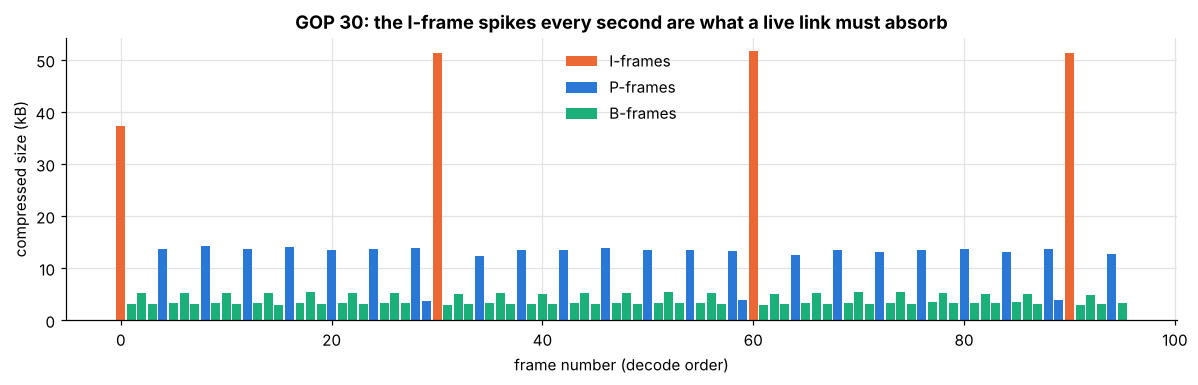

In [14]:
ft = ftypes["GOP 30"].iloc[:96]
colors = {"I": PALETTE[1], "P": PALETTE[0], "B": PALETTE[2]}
fig, ax = plt.subplots(figsize=(11, 3.6))
for t in ("I", "P", "B"):
    sel = ft[ft.type == t]
    ax.bar(sel.index, sel["size"] / 1e3, color=colors[t], width=0.85, label=f"{t}-frames")
ax.set_xlabel("frame number (decode order)"); ax.set_ylabel("compressed size (kB)")
ax.set_title("GOP 30: the I-frame spikes every second are what a live link must absorb"); ax.legend()
plt.tight_layout(); plt.show()

<div align="center">

### 5.1 Simulating packet loss on the tether

</div>


Now we break things on purpose. We stream-encode three variants as **MPEG-TS** (the container used for UDP streaming), with **no B-frames** (`-tune zerolatency`) and a **capped bitrate**, as a live ROV stream would be:

1. **GOP 30** — an I-frame every second.
2. **GOP 150** — an I-frame every 5 seconds.
3. **Periodic intra refresh** — *no* I-frames at all after the first. Instead, a vertical column of intra-coded blocks sweeps across the picture over 30 frames, so the image "heals" continuously. This removes the I-frame bitrate spikes, which is why it is popular in low-latency links (drones, video conferencing).

Then we **delete 42 consecutive MPEG-TS packets** (≈ 6 UDP datagrams, ≈ 8 kB), decode the damaged file, and measure PSNR of every frame against the original. We repeat the loss at three different moments (1.4 s, 2.5 s, 3.3 s), because recovery depends on *where in the GOP or refresh cycle* the loss lands.

variant,loss at 1.4s,loss at 2.5s,loss at 3.3s,mean damaged (s),worst (s)
GOP 30 (I-frame every 1 s),0.57,0.47,0.67,0.57,0.67
GOP 150 (I-frame every 5 s),3.57,1.40,1.67,2.21,3.57
Intra refresh over 30 frames,0.47,0.67,0.67,0.60,0.67


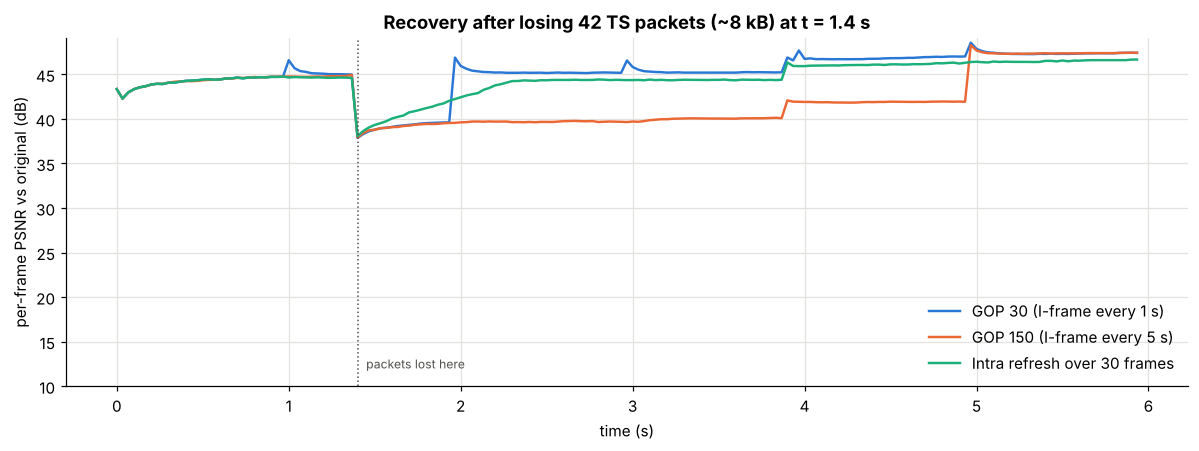

In [15]:
LOSS_T = 1.4                       # the loss we plot and look at
LOSS_TIMES = [1.4, 2.5, 3.3]       # repeat at three positions — one loss point is an anecdote, not a measurement
DROP_TS_PACKETS = 42               # 6 UDP datagrams × 7 TS packets
VARIANTS = {
    "GOP 30 (I-frame every 1 s)":   ["-g", "30", "-keyint_min", "30", "-sc_threshold", "0"],
    "GOP 150 (I-frame every 5 s)":  ["-g", "150", "-keyint_min", "150", "-sc_threshold", "0"],
    "Intra refresh over 30 frames": ["-g", "30", "-sc_threshold", "0", "-x264-params", "intra-refresh=1"],
}

def damage_seconds(clean, damaged):
    """Duration between the first and last frame that is > 3 dB worse than the undamaged encode."""
    n = min(len(clean), len(damaged)); bad = np.where(clean[:n] - damaged[:n] > 3)[0]
    return (bad.max() - bad.min() + 1) / FPS if len(bad) else 0.0

loss, rows = {}, []
for label, extra in VARIANTS.items():
    tag = re.sub(r"\W+", "_", label)[:20]
    ts = WORK / f"e5_{tag}.ts"
    # -threads 1: multi-threaded x264 with a capped bitrate is not bit-exact between runs; one thread makes this reproducible
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "veryfast",
         "-tune", "zerolatency", "-threads", "1", "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra,
         "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); start_pts = pk["pts"].min(); data = ts.read_bytes()
    _, _, pf_clean = quality(ts, SRC, per_frame=True)
    durations = []
    for k, t_loss in enumerate(LOSS_TIMES):
        pos = int(pk.loc[(pk["pts"] - start_pts - t_loss).abs().idxmin(), "pos"]); pos -= pos % 188   # TS packet boundary
        damaged = WORK / f"e5_{tag}_damaged{k}.ts"
        damaged.write_bytes(data[:pos] + data[pos + 188 * DROP_TS_PACKETS:])
        dec = WORK / (f"e5_{tag}_decoded.mkv" if k == 0 else f"e5_{tag}_decoded{k}.mkv")
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(damaged), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
        _, _, pf_dam = quality(dec, SRC, per_frame=True)
        durations.append(damage_seconds(pf_clean, pf_dam))
        if k == 0: loss[label] = {"clean": pf_clean, "damaged": pf_dam, "ts": ts}
    rows.append({"variant": label, **{f"loss at {t}s": d for t, d in zip(LOSS_TIMES, durations)},
                 "mean damaged (s)": np.mean(durations), "worst (s)": np.max(durations)})
e5_loss = pd.DataFrame(rows)
display(e5_loss.style.format({c: "{:.2f}" for c in e5_loss.columns if c != "variant"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.2))
for k, (label, d) in enumerate(loss.items()):
    ax.plot(np.arange(len(d["damaged"])) / FPS, d["damaged"], label=label, color=PALETTE[k], lw=1.6)
ax.axvline(LOSS_T, color="#52514e", ls=":", lw=1); ax.text(LOSS_T + 0.05, 12, "packets lost here", fontsize=8, color="#52514e")
ax.set_ylim(10, None); ax.set_xlabel("time (s)"); ax.set_ylabel("per-frame PSNR vs original (dB)")
ax.set_title(f"Recovery after losing {DROP_TS_PACKETS} TS packets (~{DROP_TS_PACKETS*188/1000:.0f} kB) at t = {LOSS_T} s"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

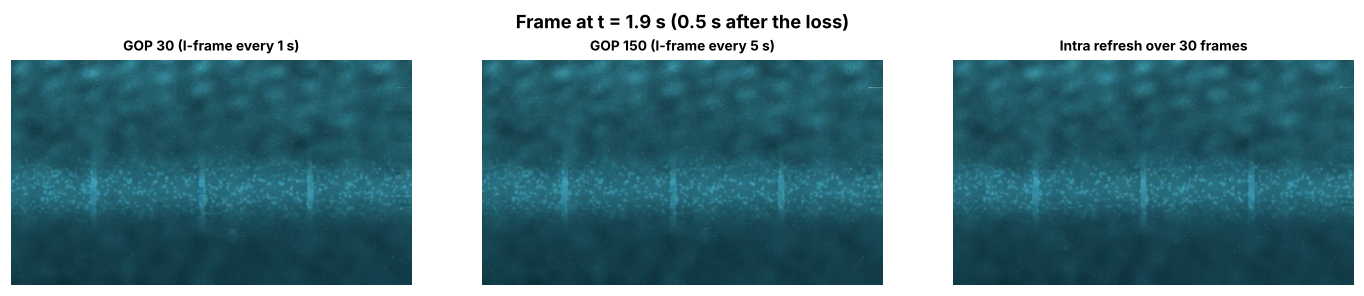

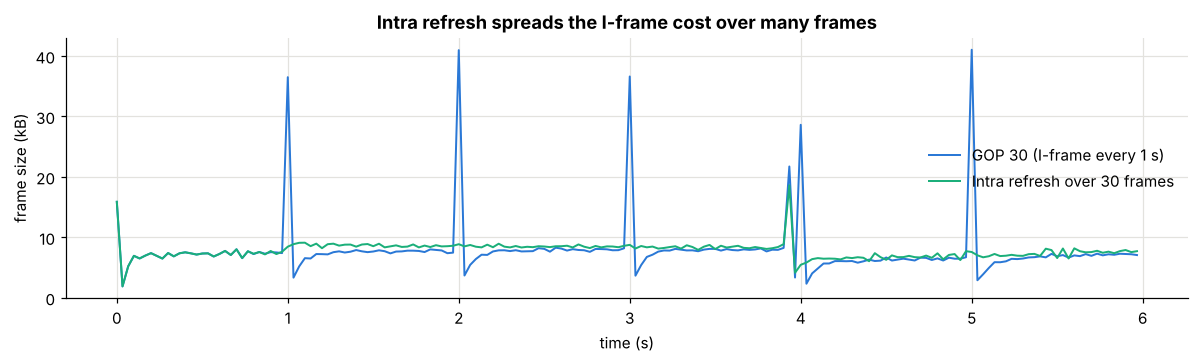

In [16]:
# What the pilot sees 0.5 s after the loss, and the bitrate smoothness of intra refresh
fig, axs = plt.subplots(1, 3, figsize=(13, 2.7))
for ax, (label, d) in zip(axs, loss.items()):
    tag = re.sub(r"\W+", "_", label)[:20]; png = WORK / f"e5_{tag}_after.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(LOSS_T + 0.5), "-i", str(WORK / f"e5_{tag}_decoded.mkv"), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.suptitle(f"Frame at t = {LOSS_T + 0.5:.1f} s (0.5 s after the loss)", fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.4))
for k, label in enumerate(["GOP 30 (I-frame every 1 s)", "Intra refresh over 30 frames"]):
    pk = packets(loss[label]["ts"]); ax.plot(np.arange(len(pk)) / FPS, pk["size"] / 1e3, label=label, color=PALETTE[[0, 2][k]], lw=1.3)
ax.set_xlabel("time (s)"); ax.set_ylabel("frame size (kB)"); ax.set_title("Intra refresh spreads the I-frame cost over many frames")
ax.legend(); plt.tight_layout(); plt.show()

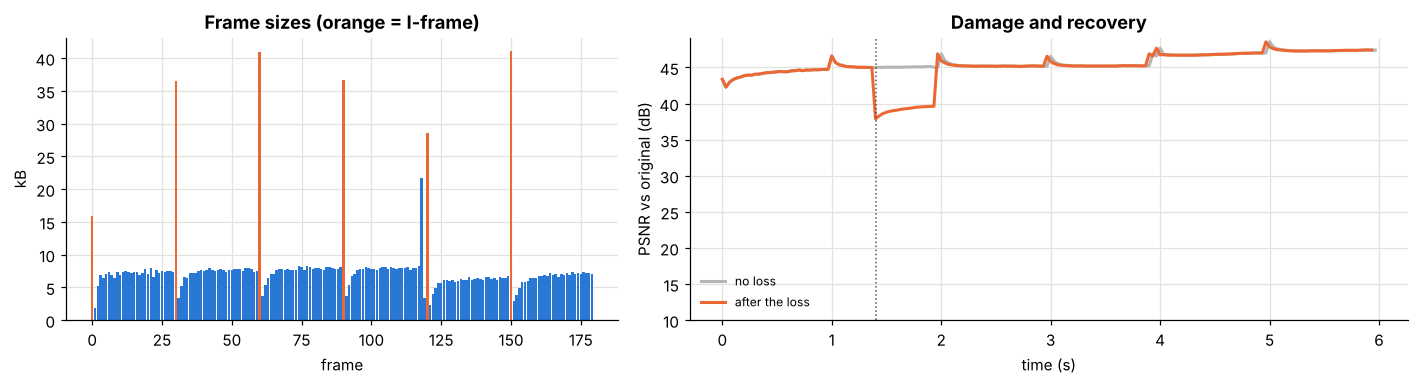

In [17]:
def tune_gop(gop_s, intra_refresh, loss_kb, loss_at):
    g = max(1, int(round(gop_s * FPS)))
    extra = (["-g", str(g), "-sc_threshold", "0", "-x264-params", "intra-refresh=1"] if intra_refresh
             else ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    args = ["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-threads", "1",
            "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra]
    key = hashlib.sha1(json.dumps(args).encode()).hexdigest()[:12]
    ts = WORK / f"tune_e5_{key}.ts"
    if not ts.exists():
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *args, "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); data = ts.read_bytes()
    _, _, clean = quality(ts, SRC, per_frame=True)
    pos = int(pk.loc[(pk["pts"] - pk["pts"].min() - loss_at).abs().idxmin(), "pos"]); pos -= pos % 188
    n_drop = max(1, int(loss_kb * 1000 / 188))
    dam = WORK / "tune_e5_damaged.ts"; dam.write_bytes(data[:pos] + data[pos + 188 * n_drop:])
    dec = WORK / "tune_e5_decoded.mkv"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(dam), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
    _, _, broken = quality(dec, SRC, per_frame=True)
    mbps = len(data) * 8 / (N_FRAMES / FPS) / 1e6
    cards([("I-frames", f"{int(pk['key'].sum())}", "intra refresh: only the first" if intra_refresh else f"one every {g / FPS:.2f} s"),
           ("stream bitrate", f"{mbps:.2f} Mb/s", "incl. MPEG-TS overhead"),
           ("biggest frame", f"{pk['size'].max() / 1e3:.0f} kB", f"average {pk['size'].mean() / 1e3:.1f} kB"),
           ("broken picture", f"{damage_seconds(clean, broken):.2f} s", f"after losing {n_drop * 188 / 1000:.0f} kB",
            damage_seconds(clean, broken) <= 1.0),
           ("worst join wait", f"{g / FPS:.2f} s", "camera switch / new viewer")])
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
    axs[0].bar(np.arange(len(pk)), pk["size"] / 1e3, width=0.9, color=[PALETTE[1] if k else PALETTE[0] for k in pk["key"]])
    axs[0].set_xlabel("frame"); axs[0].set_ylabel("kB"); axs[0].set_title("Frame sizes (orange = I-frame)")
    tt = np.arange(len(broken)) / FPS
    axs[1].plot(np.arange(len(clean)) / FPS, clean, color="#b5b5b5", label="no loss")
    axs[1].plot(tt, broken, color=PALETTE[1], label="after the loss")
    axs[1].axvline(loss_at, color="#52514e", ls=":", lw=1); axs[1].set_ylim(10, None)
    axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("PSNR vs original (dB)"); axs[1].set_title("Damage and recovery"); axs[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

tuning_panel("e5", "Keyframes and packet loss", "Shorter GOP or intra refresh: how fast does the picture heal?",
             {"gop_s": ("options", [0.25, 0.5, 1.0, 2.0, 3.0, 5.0], 1.0, "keyframe every (s)"),
              "loss_kb": ("int", (1, 40, 1), 8, "data lost (kB)"),
              "loss_at": ("float", (0.5, 4.5, 0.1), 1.4, "loss at (s)"),
              "intra_refresh": ("check", None, False, "intra refresh instead of I-frames")}, tune_gop)

**Interpretation.**

* With a **long GOP**, a single burst of loss corrupts the picture for seconds: the decoder keeps predicting from a broken reference. With a **short GOP**, the damage lasts at most until the next I-frame. **Intra refresh** heals progressively, within about one refresh period (here 0.5–0.7 s for a 30-frame refresh at 30 FPS) — *and* it has no I-frame bitrate spikes.
* Look at the GOP 150 row: the damage lasts until the next I-frame at t = 5 s (3.6 s for the loss at 1.4 s). For the loss at 2.5 s it stopped earlier, at the camera **cut** at t ≈ 4 s, because that frame is coded almost entirely with intra blocks. Being rescued by a lucky scene change is not a design — plan for the worst case.
* The short-GOP cost is bitrate (the table above). On a reliable, short, wired tether with little loss, 1–2 s GOPs are a common compromise; if you see loss, shorten the GOP or use intra refresh — and **find the cause of the loss** (ROV Experiments E6 and E10).
* **Switching cameras** in the pilot UI has the same physics: a player that starts a new stream mid-GOP shows nothing until an I-frame arrives. If camera switching "takes a second or two", your GOP is probably 1–2 s long. Options: shorter GOP, request a keyframe on switch, or keep a decoder running per camera (substreams!).

<div align="center">

### Exercises

</div>

1. Change `DROP_TS_PACKETS` to 7 (a single UDP datagram). Is the damage still visible?
2. Why does TCP (e.g. RTSP-over-TCP, HTTP) not show this kind of corruption — and what does it show instead when the link is congested? *(Hint: retransmission → growing delay → frozen video.)*
3. Your pilot complains: "When I switch to the rear camera it takes about 2 seconds to appear." Write down two hypotheses and the measurement that would distinguish them.

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 6</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Measuring quality objectively: PSNR, SSIM, VMAF</h2>
</div>


**Question.** "It looks fine to me" is not a measurement. How do professionals put a number on video quality — and when should we not trust that number?

<div align="center">

### PSNR — Peak Signal-to-Noise Ratio

</div>

For an 8-bit image $I$ (original) and $K$ (compressed), both $W \times H$:

$$
\text{MSE} = \frac{1}{WH}\sum_{x,y}\big(I(x,y)-K(x,y)\big)^2, \qquad
\text{PSNR} = 10\log_{10}\frac{255^2}{\text{MSE}} \;\; [\text{dB}]
$$

* Higher is better. Rough guide for 8-bit video: < 30 dB clearly degraded, 35–40 dB good, > 45 dB nearly transparent.
* +6 dB ≈ halving the average pixel error. PSNR is cheap, simple, and **blind to how humans see**: every pixel error counts the same, whether it is in a smooth gradient or invisible in texture.

<div align="center">

### SSIM — Structural Similarity

</div>

SSIM compares local windows of the two images on three things humans notice: brightness ($\mu$), contrast ($\sigma$), and structure (correlation $\sigma_{xy}$):

$$
\text{SSIM}(x,y) = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)}
$$

averaged over all windows. 1.0 = identical. Values above ~0.95 are usually good; SSIM is much more sensitive to blur and blocking than PSNR.

<div align="center">

### VMAF — Video Multi-method Assessment Fusion

</div>

Netflix's metric: several elementary features (detail loss, visual information fidelity, motion) are fused by a machine-learning model **trained on human opinion scores** for TV/film viewing. 0–100 scale. It correlates best with human opinion *for entertainment content on a TV*. It needs FFmpeg built with `libvmaf`.

<div align="center">

### Limitations — read this twice

</div>

* All three are **full-reference** metrics: they need the original. On the live ROV you don't have it; you measure in the lab, then choose settings.
* They measure *fidelity to the original*, not *usefulness to the pilot*. A pilot needs to read a gauge, see a crack, judge distance. A metric trained on movies does not know that.
* Underwater footage (noise, particles, haze) can be scored "badly" by PSNR simply because the encoder removed sensor noise — which may actually look *better*.
* So: **use metrics to compare settings; use pilots to decide what is good enough.**

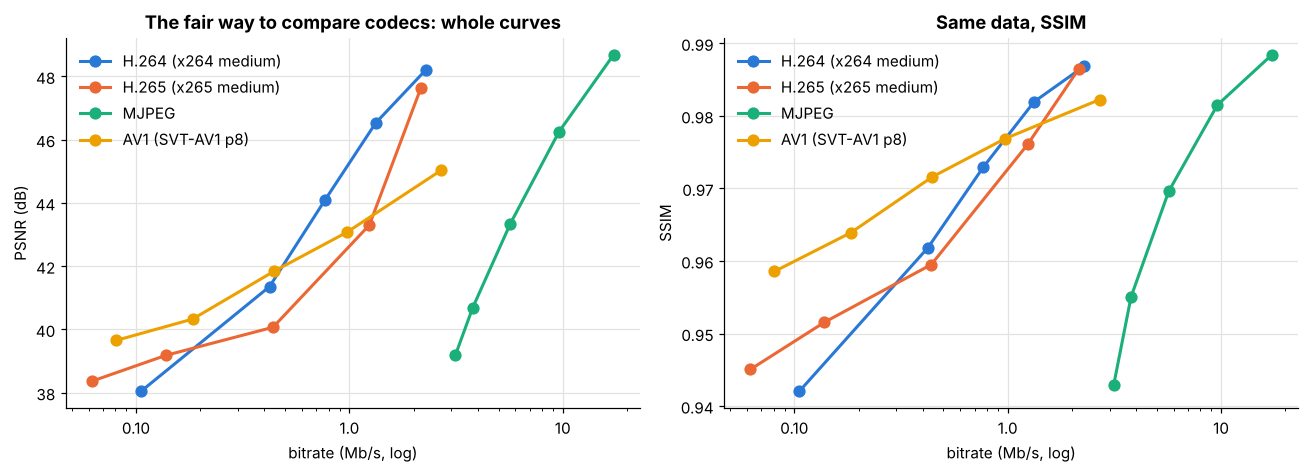

In [18]:
CURVES = {
    # Metric-neutral tuning: -tune ssim (x264/x265) and tune=1 (PSNR) for SVT-AV1 — see the note below.
    "H.264 (x264 medium)":  ("libx264",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx264", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p"], "mp4"),
    "H.265 (x265 medium)":  ("libx265",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx265", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p", "-x265-params", "log-level=error"], "mp4"),
    "MJPEG":                ("mjpeg",     [2, 4, 8, 16, 31],    lambda q: ["-c:v", "mjpeg", "-q:v", str(q), "-pix_fmt", "yuvj420p"], "mkv"),
    "AV1 (SVT-AV1 p8)":     ("libsvtav1", [24, 32, 40, 48, 56], lambda q: ["-c:v", "libsvtav1", "-preset", "8", "-crf", str(q), "-svtav1-params", "tune=1", "-pix_fmt", "yuv420p"], "mkv"),
}
rows = []
for codec, (enc, qs, mk, ext) in CURVES.items():
    if not HAS.get(enc): print("skip", codec); continue
    for q in qs:
        out = WORK / f"e6_{enc}_{q}.{ext}"
        if not out.exists():
            run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *mk(q), "-an", str(out)])
        p = probe(out); psnr, ssim = quality(out, SRC)
        rows.append({"codec": codec, "q": q, "bitrate_Mb/s": p["bitrate_mbps"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e6 = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (codec, g) in enumerate(e6.groupby("codec", sort=False)):
    for ax, m in zip(axs, ("PSNR_dB", "SSIM")):
        ax.plot(g["bitrate_Mb/s"], g[m], "o-", color=PALETTE[k], label=codec)
for ax, m in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt)); ax.set_xlabel("bitrate (Mb/s, log)"); ax.set_ylabel(m); ax.legend()
axs[0].set_title("The fair way to compare codecs: whole curves"); axs[1].set_title("Same data, SSIM")
plt.tight_layout(); plt.show()

> **Why `-tune ssim`?** By default x264, x265 and SVT-AV1 use *psychovisual* optimisations (psy-RD, adaptive quantization) that make video look better to people but deliberately *lower* PSNR/SSIM. If you compare codecs with a metric while each encoder optimises for something else, you are measuring the tuning, not the codec. So for this comparison every encoder is tuned for the metric. For the pilot's live view you would normally keep the default (subjective) tuning.

**Reading the curves:** a curve that is further **left** reaches the same quality with fewer bits. The horizontal distance between two curves at the same quality is the bitrate saving — this is the idea behind the industry's **BD-rate** (Bjøntegaard delta rate) metric.

Below we interpolate each curve to find the bitrate needed for the same quality — we use the SSIM that x264 reaches at its default CRF 23 as the target — and express it as **bits per pixel** — the number we will reuse to size the eight-camera system in Experiment 7.

In [19]:
def bitrate_at(g, metric, target):
    g = g.sort_values(metric)
    if not (g[metric].min() <= target <= g[metric].max()): return np.nan
    return float(np.exp(np.interp(target, g[metric], np.log(g["bitrate_Mb/s"]))))

# Two operating points: a constrained-tether point (SSIM 0.96) and the quality x264 reaches at its default CRF 23.
lo = e6.groupby("codec")["SSIM"].min().max(); hi = e6.groupby("codec")["SSIM"].max().min()
ssim_crf23 = float(e6[(e6.codec == "H.264 (x264 medium)") & (e6.q == 23)].SSIM.iloc[0])   # x264 CRF 23, tune ssim
SSIM_TARGET = round(float(np.clip(ssim_crf23, lo + 0.001, hi - 0.001)), 3)
SSIM_LOW = round(float(np.clip(0.96, lo + 0.001, hi - 0.001)), 3)
rows = []
for codec, g in e6.groupby("codec", sort=False):
    r_lo, r_hi = bitrate_at(g, "SSIM", SSIM_LOW), bitrate_at(g, "SSIM", SSIM_TARGET)
    rows.append({"codec": codec, f"Mb/s @ SSIM {SSIM_LOW}": r_lo, f"Mb/s @ SSIM {SSIM_TARGET}": r_hi,
                 "bits_per_pixel (high)": r_hi * 1e6 / (W * H * FPS)})
equal_q = pd.DataFrame(rows)
for col_ in (f"Mb/s @ SSIM {SSIM_LOW}", f"Mb/s @ SSIM {SSIM_TARGET}"):
    ref = equal_q.loc[equal_q.codec.str.startswith("H.264"), col_].iloc[0]
    equal_q["vs H.264 " + col_.split("@ ")[1]] = equal_q[col_] / ref
display(equal_q.style.format({c: ("{:.2f}×" if c.startswith("vs") else "{:.4f}" if "bits" in c else "{:.2f}") for c in equal_q.columns if c != "codec"}).hide(axis="index"))
CODEC_BPP = dict(zip(equal_q.codec.str.split(" ").str[0], equal_q["bits_per_pixel (high)"]))   # e.g. {"H.264": 0.045, ...}
print("Calibrated bits-per-pixel (used in Experiment 7):", {k: round(v, 4) for k, v in CODEC_BPP.items()})

codec,Mb/s @ SSIM 0.96,Mb/s @ SSIM 0.981,bits_per_pixel (high),vs H.264 SSIM 0.96,vs H.264 SSIM 0.981
H.264 (x264 medium),0.37,1.25,0.0454,1.00×,1.00×
H.265 (x265 medium),0.45,1.61,0.0583,1.22×,1.28×
MJPEG,4.35,9.40,0.3400,11.69×,7.49×
AV1 (SVT-AV1 p8),0.10,2.13,0.0770,0.27×,1.70×


Calibrated bits-per-pixel (used in Experiment 7): {'H.264': 0.0454, 'H.265': 0.0583, 'MJPEG': 0.34, 'AV1': 0.077}


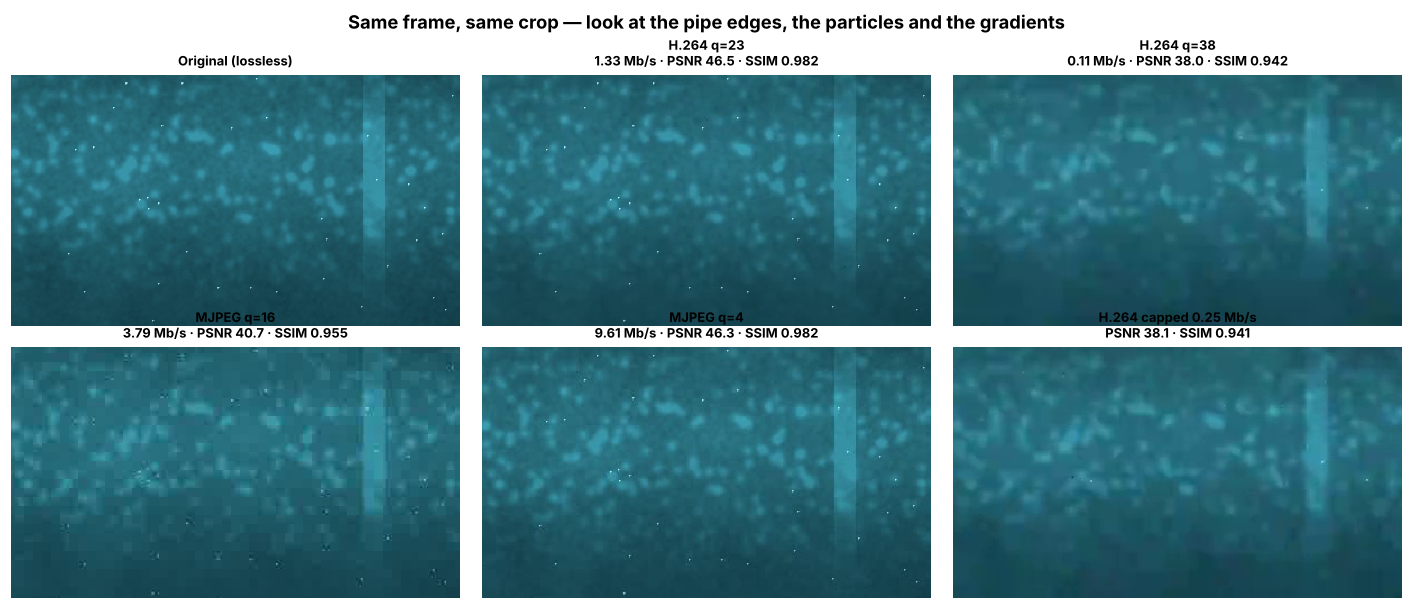

In [20]:
# Visual comparison: zoom into the pipeline area of one frame
T_SHOW, CROP = 2.0, "crop=400:225:620:330"
picks = [("Original (lossless)", SRC, None)]
def pick(codec, q):
    r = e6[(e6.codec == codec) & (e6.q == q)].iloc[0]; return (f"{codec.split(' ')[0]} q={q}\n{r['bitrate_Mb/s']:.2f} Mb/s · PSNR {r.PSNR_dB:.1f} · SSIM {r.SSIM:.3f}", r.file, r)
picks += [pick("H.264 (x264 medium)", 23), pick("H.264 (x264 medium)", 38), pick("MJPEG", 16), pick("MJPEG", 4)]
low = e3[(e3["mode"] != "CRF")].iloc[0]
picks.append((f"H.264 capped {low.setting}\nPSNR {low.PSNR_dB:.1f} · SSIM {low.SSIM:.3f}", low.file, None))
fig, axs = plt.subplots(2, 3, figsize=(13, 5.6))
for ax, (title, path, _) in zip(axs.flat, picks):
    png = WORK / f"e6_crop_{Path(str(path)).stem}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(T_SHOW), "-i", str(path), "-frames:v", "1", "-vf", CROP, str(png)])
    ax.imshow(plt.imread(png), interpolation="nearest"); ax.set_title(title, fontsize=8.5); ax.axis("off")
plt.suptitle("Same frame, same crop — look at the pipe edges, the particles and the gradients", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation — the curves cross.** On this clip, AV1 needs *far fewer* bits than H.264 at the low-bitrate (tight-tether) end, and H.265 is roughly level with H.264 there and only pulls ahead at even lower bitrates; at the high-quality end x264 is as good or better than both. Published comparisons on natural camera footage usually report larger savings for H.265 and AV1; our synthetic clip (a rigid texture panning by whole pixels, plus noise) happens to suit H.264's tools well. Two lessons:

1. **"Which codec is better?" has no answer without an operating point and content.** On a tight tether you live at the left of these curves — exactly where the newer codecs gain most (if your hardware can encode them in real time).
2. **Repeat this experiment with your own footage** (`ROV_SOURCE`) before choosing. Then check that the encoder exists in hardware on your SBC and that the pilot's browser can decode it — compression efficiency is only one of four constraints.

For sizing the eight-camera system (Experiment 7) we use the conservative high-quality point.

<div align="center">

### 6.1 When metrics disagree with your eyes

</div>


We take one frame and apply three distortions to it — then ask PSNR and SSIM to rank them.

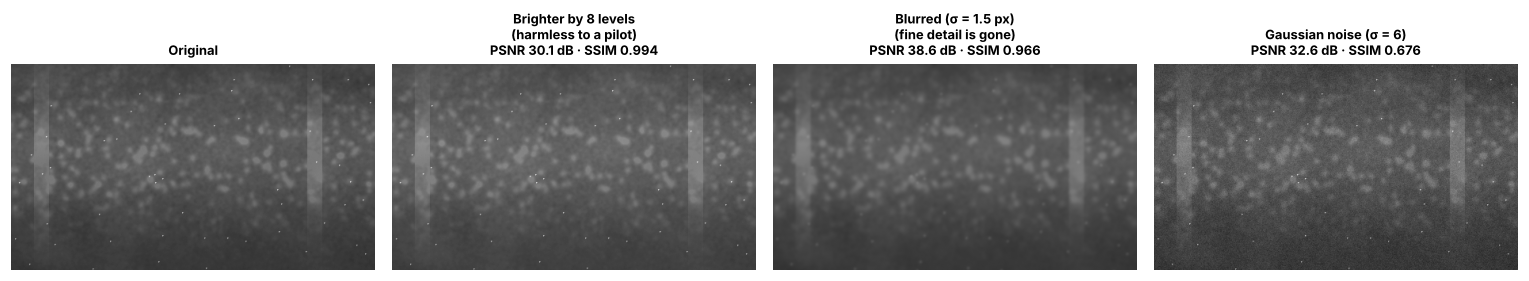

In [21]:
from scipy.ndimage import gaussian_filter
png = WORK / "e6_ref_frame.png"
run([FFMPEG, "-y", "-loglevel", "error", "-ss", "2.0", "-i", str(SRC), "-frames:v", "1", "-vf", "format=gray", str(png)])
ref_y = (plt.imread(png)[..., 0] if plt.imread(png).ndim == 3 else plt.imread(png)) * 255.0

def psnr_np(a, b):
    mse = np.mean((a - b) ** 2); return 99.0 if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def ssim_np(a, b, sigma=1.5):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, mu_b = gaussian_filter(a, sigma), gaussian_filter(b, sigma)
    s_a = gaussian_filter(a * a, sigma) - mu_a ** 2; s_b = gaussian_filter(b * b, sigma) - mu_b ** 2
    s_ab = gaussian_filter(a * b, sigma) - mu_a * mu_b
    m = ((2 * mu_a * mu_b + C1) * (2 * s_ab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (s_a + s_b + C2))
    return float(m.mean())

rng = np.random.default_rng(0)
tests = {"Original": ref_y,
         "Brighter by 8 levels\n(harmless to a pilot)": np.clip(ref_y + 8, 0, 255),
         "Blurred (σ = 1.5 px)\n(fine detail is gone)": gaussian_filter(ref_y, 1.5),
         "Gaussian noise (σ = 6)": np.clip(ref_y + rng.normal(0, 6, ref_y.shape), 0, 255)}
fig, axs = plt.subplots(1, 4, figsize=(14, 2.9))
for ax, (name, img) in zip(axs, tests.items()):
    ax.imshow(img[300:560, 560:1020], cmap="gray", vmin=0, vmax=255)
    ax.set_title(name if name == "Original" else f"{name}\nPSNR {psnr_np(ref_y, img):.1f} dB · SSIM {ssim_np(ref_y, img):.3f}", fontsize=8.5)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation.** PSNR punishes the harmless brightness shift heavily but forgives the blur that removed real detail; SSIM gets that ranking closer to human judgement. Neither knows that, for a pilot, the blur might hide a crack, and the noise might hide nothing important. **Metrics are for comparing settings consistently; pilots decide what is acceptable.** (Activity 3 in the workshop turns this into a blind test.)

In [22]:
if HAS["libvmaf"]:
    for q in (23, 38):
        f = e6[(e6.codec == "H.264 (x264 medium)") & (e6.q == q)].iloc[0].file
        r = run([FFMPEG, "-hide_banner", "-i", str(f), "-i", str(SRC), "-lavfi", "[0:v][1:v]libvmaf", "-f", "null", "-"])
        print(f"x264 CRF {q}: VMAF =", re.search(r"VMAF score: ([\d.]+)", r["stderr"]).group(1))
else:
    print("VMAF is not available in this FFmpeg build (no 'libvmaf' filter).")
    print("To try it: install an FFmpeg build with --enable-libvmaf (e.g. the static builds linked from ffmpeg.org),")
    print("then run:  ffmpeg -i distorted.mp4 -i reference.mkv -lavfi \"[0:v][1:v]libvmaf\" -f null -")

VMAF is not available in this FFmpeg build (no 'libvmaf' filter).
To try it: install an FFmpeg build with --enable-libvmaf (e.g. the static builds linked from ffmpeg.org),
then run:  ffmpeg -i distorted.mp4 -i reference.mkv -lavfi "[0:v][1:v]libvmaf" -f null -


<div align="center">

### Exercises

</div>

1. Find the x264 CRF at which **your pilots** can no longer read a depth gauge or a number painted on a prop in a recorded clip. What is its SSIM? Now you have a *requirement* backed by a measurement.
2. Where on the rate–quality chart is MJPEG most competitive? Why could MJPEG still be the right choice for one specific camera on your ROV?
3. Compute the bitrate saving of H.265 vs H.264 at your SSIM target. Does it justify the extra encoding cost on your SBC — and can your topside **browser** decode H.265?

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 7</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">The eight-camera ROV simulator</h2>
</div>


**Question.** Given N cameras, codecs and a tether, does the system fit — with headroom?

**Model.**

$$
R_{\text{camera}} \approx \text{bpp}_{\text{codec}} \times W \times H \times f \times \Big(\tfrac{P_{\text{ref}}}{W H}\Big)^{0.25},
\qquad
R_{\text{wire}} = R_{\text{camera}} \times (1 + \text{overhead}),
\qquad
U = \frac{\sum R_{\text{wire}}}{C_{\text{link}}}
$$

* $\text{bpp}_{\text{codec}}$ comes from **Experiment 6** (bits per pixel at equal, high quality on *our* clip — recalibrate with your footage). **Real camera footage usually needs more bits than our synthetic clip**: if the pilot view needs, say, 4–6 Mb/s at 1080p30 in your measurements, use that.
* The $(P_{\text{ref}}/WH)^{0.25}$ term is a **rule of thumb**: larger frames need slightly fewer bits per pixel because blocks are more predictable. It is an approximation — the experiment to verify it is in the exercises.
* **Protocol overhead.** Ethernet adds 38 bytes per frame on the wire (preamble 8, header 14, FCS 4, inter-frame gap 12), IPv4 adds 20, UDP 8, RTP 12. With a 1500-byte MTU: $1538/1460 \approx 1.053$ → **~5 %**. MPEG-TS over UDP adds its own 4-byte header per 188-byte packet → **~7 %**. TCP-based streams also generate ACK traffic in the reverse direction.
* **Headroom.** Don't plan above **~70 % sustained utilization**: I-frame bursts (Experiment 5), retransmissions, telemetry, control traffic and measurement error all need space. Planning at 95 % means you will be congested at peaks.

> **Important:** the control link (thrusters, manipulator, telemetry) usually shares the same tether. Video must never starve control. That is an *architectural* requirement, not a tuning detail.

In [23]:
P_REF = W * H
OVERHEAD = {"RTP/UDP": 1538 / 1460 - 1, "MPEG-TS/UDP": (1382 / 1316) * (188 / 184) - 1,
            "WebRTC (SRTP/UDP)": 0.07, "MJPEG over HTTP (TCP)": 0.06}
RES = {"320×180": (320, 180), "640×360": (640, 360), "640×480": (640, 480), "1280×720": (1280, 720), "1920×1080": (1920, 1080)}

def cam_mbps(codec, res, fps):
    w, h = RES[res]
    return CODEC_BPP[codec] * w * h * fps * (P_REF / (w * h)) ** 0.25 / 1e6

def simulate(name, cams, transport="RTP/UDP"):
    """cams: list of (count, codec, resolution, fps). Returns total on-the-wire Mb/s."""
    total = sum(n * cam_mbps(c, r, f) for n, c, r, f in cams)
    return {"scenario": name, "video_Mb/s": total, "wire_Mb/s": total * (1 + OVERHEAD[transport]), "transport": transport}

SCENARIOS = [
    simulate("8 × MJPEG 640×480@30 (a common student setup)", [(8, "MJPEG", "640×480", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × MJPEG 1280×720@30", [(8, "MJPEG", "1280×720", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × MJPEG 1920×1080@30", [(8, "MJPEG", "1920×1080", 30)], "MJPEG over HTTP (TCP)"),
    simulate("8 × H.264 1280×720@30", [(8, "H.264", "1280×720", 30)]),
    simulate("8 × H.264 1920×1080@30", [(8, "H.264", "1920×1080", 30)]),
    simulate("1 main H.264 1080p30 + 7 subs 640×360@15", [(1, "H.264", "1920×1080", 30), (7, "H.264", "640×360", 15)]),
    simulate("2 main 1080p30 + 2 subs + 4 thumbnails 320×180@5", [(2, "H.264", "1920×1080", 30), (2, "H.264", "640×360", 15), (4, "H.264", "320×180", 5)]),
]
if "H.265" in CODEC_BPP:
    SCENARIOS.append(simulate("8 × H.265 1920×1080@30", [(8, "H.265", "1920×1080", 30)]))
sim = pd.DataFrame(SCENARIOS)
LINK = 100; HEADROOM = 0.70
def verdict(x, link=LINK):
    return "OVER capacity" if x > link else ("Above 70 % — tight" if x > HEADROOM * link else "OK")
sim["on 100 Mb/s"] = sim["wire_Mb/s"].apply(lambda x: verdict(x, 100))
sim["on 1 Gb/s"] = sim["wire_Mb/s"].apply(lambda x: verdict(x, 1000))
display(sim.style.format({"video_Mb/s": "{:.1f}", "wire_Mb/s": "{:.1f}"}).hide(axis="index"))

scenario,video_Mb/s,wire_Mb/s,transport,on 100 Mb/s,on 1 Gb/s
8 × MJPEG 640×480@30 (a common student setup),33.0,35.0,MJPEG over HTTP (TCP),OK,OK
8 × MJPEG 1280×720@30,75.2,79.7,MJPEG over HTTP (TCP),Above 70 % — tight,OK
8 × MJPEG 1920×1080@30,138.2,146.5,MJPEG over HTTP (TCP),OVER capacity,OK
8 × H.264 1280×720@30,10.0,10.6,RTP/UDP,OK,OK
8 × H.264 1920×1080@30,18.4,19.4,RTP/UDP,OK,OK
1 main H.264 1080p30 + 7 subs 640×360@15,3.9,4.1,RTP/UDP,OK,OK
2 main 1080p30 + 2 subs + 4 thumbnails 320×180@5,5.2,5.4,RTP/UDP,OK,OK
8 × H.265 1920×1080@30,23.7,24.9,RTP/UDP,OK,OK


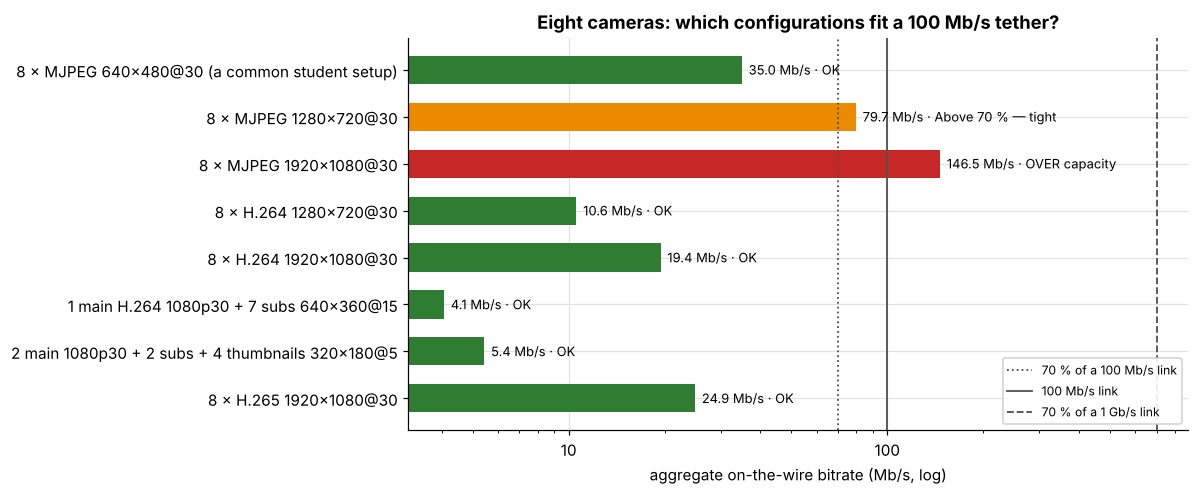

In [24]:
STATUS = {"OK": "#2e7d32", "Above 70 % — tight": "#ed8b00", "OVER capacity": CRITICAL}
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(sim))
ax.barh(y, sim["wire_Mb/s"], color=[STATUS[v] for v in sim["on 100 Mb/s"]], height=0.6)
for yi, (v, s) in enumerate(zip(sim["wire_Mb/s"], sim["on 100 Mb/s"])):
    ax.text(v * 1.05, yi, f"{v:.1f} Mb/s · {s}", va="center", fontsize=8.5)
for x_, lab, ls in ((LINK * HEADROOM, "70 % of a 100 Mb/s link", ":"), (LINK, "100 Mb/s link", "-"), (1000 * HEADROOM, "70 % of a 1 Gb/s link", "--")):
    ax.axvline(x_, color="#52514e", ls=ls, lw=1.2, label=lab)
ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
ax.set_yticks(y, sim["scenario"]); ax.invert_yaxis(); ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt))
ax.set_xlabel("aggregate on-the-wire bitrate (Mb/s, log)"); ax.set_title("Eight cameras: which configurations fit a 100 Mb/s tether?")
ax.set_xlim(right=sim["wire_Mb/s"].max() * 6); plt.tight_layout(); plt.show()

<div align="center">

### 7.1 Try it yourself

</div>


Change the camera mix in the panel below: the verdict updates instantly. To describe your exact vehicle, edit `my_design` in the next cell.

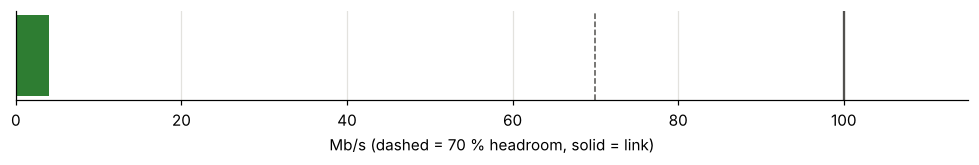

In [25]:
def explore(n_main=1, main_res="1920×1080", main_fps=30, n_sub=7, sub_res="640×360", sub_fps=15,
            codec="H.264", link_mbps=100, transport="RTP/UDP"):
    s = simulate("custom", [(n_main, codec, main_res, main_fps), (n_sub, codec, sub_res, sub_fps)], transport)
    u = s["wire_Mb/s"] / link_mbps; v = verdict(s["wire_Mb/s"], link_mbps)
    cards([("on the wire", f"{s['wire_Mb/s']:.1f} Mb/s", f"{transport}"), ("link use", f"{u:.0%}", v, v == "OK"),
           ("cameras", f"{n_main + n_sub}", f"{n_main} main + {n_sub} sub")])
    fig, ax = plt.subplots(figsize=(9, 1.6))
    ax.barh([0], [s["wire_Mb/s"]], color=STATUS[v], height=0.5)
    ax.axvline(link_mbps * HEADROOM, ls="--", color="#52514e", lw=1); ax.axvline(link_mbps, color="#52514e", lw=1.5)
    ax.set_xlim(0, max(link_mbps, s["wire_Mb/s"]) * 1.15); ax.set_yticks([]); ax.set_xlabel("Mb/s (dashed = 70 % headroom, solid = link)")
    plt.tight_layout(); plt.show()

tuning_panel("e7", "Eight-camera budget", "Instant calculation: change anything and the verdict updates",
             {"n_main": ("int", (0, 8, 1), 1, "main streams"), "main_res": ("options", list(RES), "1920×1080", "main resolution"),
              "main_fps": ("int", (5, 60, 5), 30, "main fps"), "n_sub": ("int", (0, 8, 1), 7, "substreams"),
              "sub_res": ("options", list(RES), "640×360", "sub resolution"), "sub_fps": ("int", (1, 30, 1), 15, "sub fps"),
              "codec": ("options", list(CODEC_BPP), "H.264", "codec"), "link_mbps": ("options", [100, 1000], 100, "link (Mb/s)"),
              "transport": ("options", list(OVERHEAD), "RTP/UDP", "transport")}, explore, live=True)

In [26]:
# EXERCISE: describe YOUR vehicle here (count, codec, resolution, fps) and run the cell.
my_design = [(1, "H.264", "1280×720", 30), (3, "H.264", "640×360", 15), (4, "MJPEG", "320×180", 5)]
r = simulate("my design", my_design); print(r, "→", verdict(r["wire_Mb/s"], 100), "on 100 Mb/s")

{'scenario': 'my design', 'video_Mb/s': 2.7038842891060604, 'wire_Mb/s': 2.8483383812637815, 'transport': 'RTP/UDP'} → OK on 100 Mb/s


<div align="center">

### Exercises

</div>

1. Measure `ethtool eth0 | grep Speed` on **both ends** of your tether. Is it 100 or 1000 Mb/s? Then run `iperf3` across it (ROV Experiments E6). Use the **measured** throughput as `LINK`, not the nominal one.
2. Test the $(\cdot)^{0.25}$ rule: encode the reference at 640×360 and 1920×1080 with the same CRF and compare the measured bits per pixel.
3. How many Mb/s does your **control and telemetry** traffic need? Add it to the budget.

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 8</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Main streams, substreams, and priorities</h2>
</div>


**Question.** Does every camera need full quality all the time?

**Idea.** Professional multi-camera systems (CCTV recorders, broadcast, industrial ROVs) encode each camera **twice**:

* a **main stream** — high resolution and frame rate, used when the camera is on the big screen or recorded;
* a **substream** — small and cheap, used for the thumbnail grid.

The pilot looks at one or two cameras at a time. The other six only need to answer *"is something happening there?"* — which a 640×360@15 picture answers very well.

Most IP cameras can produce a main stream and a substream themselves. If your SBC encodes, it can produce both from one capture (GStreamer `tee`, or FFmpeg with two outputs) — at the cost of encoder capacity (Experiment 10).

,bitrate_Mb/s,SSIM (upscaled to 720p)
"main 1280×720@30, 2.5 Mb/s",2.476,0.983
"sub 640×360@15, 0.4 Mb/s",0.417,0.955
"thumb 320×180@10, 0.12 Mb/s",0.125,0.939


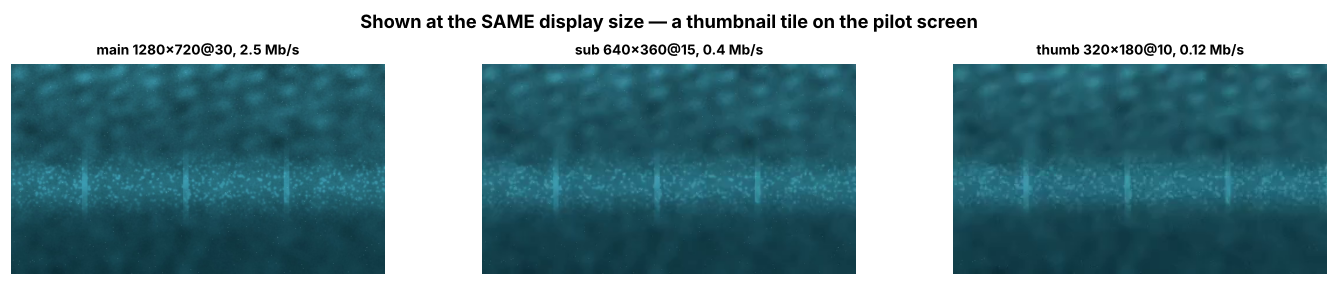

In [27]:
STREAMS = {
    "main 1280×720@30, 2.5 Mb/s":  (1280, 720, 30, 2500),
    "sub 640×360@15, 0.4 Mb/s":    (640, 360, 15, 400),
    "thumb 320×180@10, 0.12 Mb/s": (320, 180, 10, 120),
}
rows = {}
for label, (w, h, fps, kb) in STREAMS.items():
    out = WORK / f"e8_{w}x{h}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}:flags=area,fps={fps}",
             "-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-b:v", f"{kb}k", "-maxrate", f"{kb}k",
             "-bufsize", f"{kb // 2}k", "-g", str(fps), "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)   # scored after upscaling back to 1280×720
    rows[label] = {"bitrate_Mb/s": p["bitrate_mbps"], "SSIM (upscaled to 720p)": ssim, "file": out}
e8 = pd.DataFrame(rows).T
display(e8.drop(columns="file").astype(float).style.format("{:.3f}"))

fig, axs = plt.subplots(1, 3, figsize=(13, 2.6))
for ax, (label, row) in zip(axs, rows.items()):
    png = WORK / f"e8_{Path(str(row['file'])).stem}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", "2.0", "-i", str(row["file"]), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.suptitle("Shown at the SAME display size — a thumbnail tile on the pilot screen", fontweight="bold"); plt.tight_layout(); plt.show()

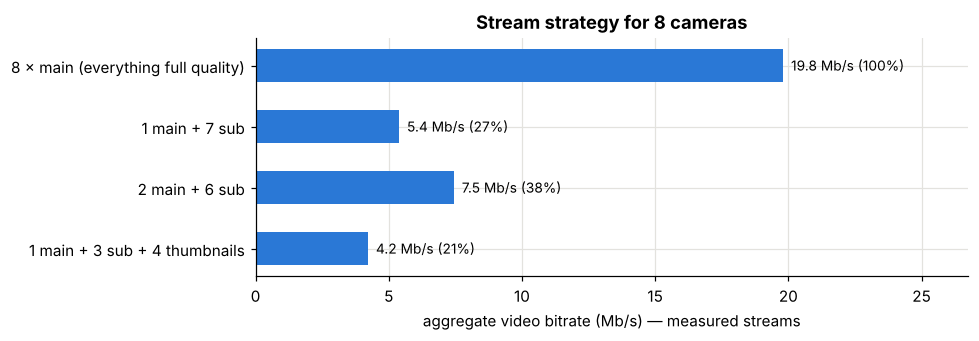

In [28]:
m, s, t = (float(e8.iloc[i]["bitrate_Mb/s"]) for i in range(3))
strategies = {"8 × main (everything full quality)": 8 * m, "1 main + 7 sub": m + 7 * s, "2 main + 6 sub": 2 * m + 6 * s,
              "1 main + 3 sub + 4 thumbnails": m + 3 * s + 4 * t}
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(list(strategies), list(strategies.values()), color=PALETTE[0], height=0.55)
for yi, v in enumerate(strategies.values()):
    ax.text(v, yi, f"  {v:.1f} Mb/s ({v / strategies['8 × main (everything full quality)']:.0%})", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("aggregate video bitrate (Mb/s) — measured streams"); ax.set_title("Stream strategy for 8 cameras")
ax.set_xlim(right=max(strategies.values()) * 1.35); plt.tight_layout(); plt.show()

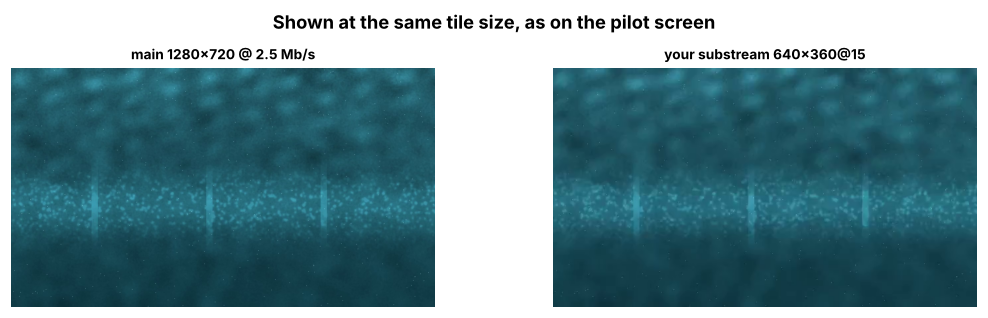

In [29]:
def tune_substream(width, fps, kbps):
    w = int(width); h = int(round(w * 9 / 16 / 2) * 2)
    args = ["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-b:v", f"{kbps}k", "-maxrate", f"{kbps}k",
            "-bufsize", f"{kbps // 2}k", "-g", str(fps)]
    res = encode_cached(args, "e8", vf=f"scale={w}:{h}:flags=area,fps={fps}")
    main = float(e8.iloc[0]["bitrate_Mb/s"]); total = main + 7 * res["bitrate"]
    cards([("substream", f"{res['bitrate']:.2f} Mb/s", f"{w}×{h} @ {fps} fps"),
           ("SSIM (upscaled)", f"{res['ssim']:.3f}", "0.95+ is fine for a thumbnail", res["ssim"] >= 0.95),
           ("1 main + 7 of these", f"{total:.1f} Mb/s", f"{total / (8 * main):.0%} of eight main streams", True),
           ("saving", f"{8 * main - total:.1f} Mb/s", "free for the pilot view or headroom")])
    fig, axs = plt.subplots(1, 2, figsize=(10, 2.9))
    for ax, (path, cap) in zip(axs, ((e8.iloc[0]["file"], "main 1280×720 @ 2.5 Mb/s"), (res["file"], f"your substream {w}×{h}@{fps}"))):
        ax.imshow(frame_png(path, 2.0, "e8_" + str(abs(hash(cap)))), extent=(0, 16, 0, 9)); ax.set_title(cap, fontsize=9); ax.axis("off")
    plt.suptitle("Shown at the same tile size, as on the pilot screen", fontweight="bold"); plt.tight_layout(); plt.show()

tuning_panel("e8", "Design a substream", "How small can a thumbnail stream be before it stops being useful?",
             {"width": ("options", [256, 320, 426, 512, 640, 854, 960], 640, "width (16:9)"),
              "fps": ("int", (2, 30, 1), 15, "fps"),
              "kbps": ("options", [60, 100, 150, 250, 400, 600, 1000], 400, "bitrate (kb/s)")}, tune_substream)

<div align="center">

### 8.1 Camera priorities and dynamic adjustment

</div>


A better system does not use fixed bitrates at all. It decides, every second or so, **how to spend the available budget**, guided by priorities:

1. Every *active* camera first gets its **minimum** bitrate, in priority order. If even the minimums do not fit, the lowest-priority cameras are **paused** (and the UI must show that clearly — see the UX section!).
2. Leftover budget is given to cameras in priority order, up to each camera's **maximum**.

Below, the tether capacity drops (e.g. a damaged connector forces 100 → 40 → 20 Mb/s), and the allocator protects the pilot's view.

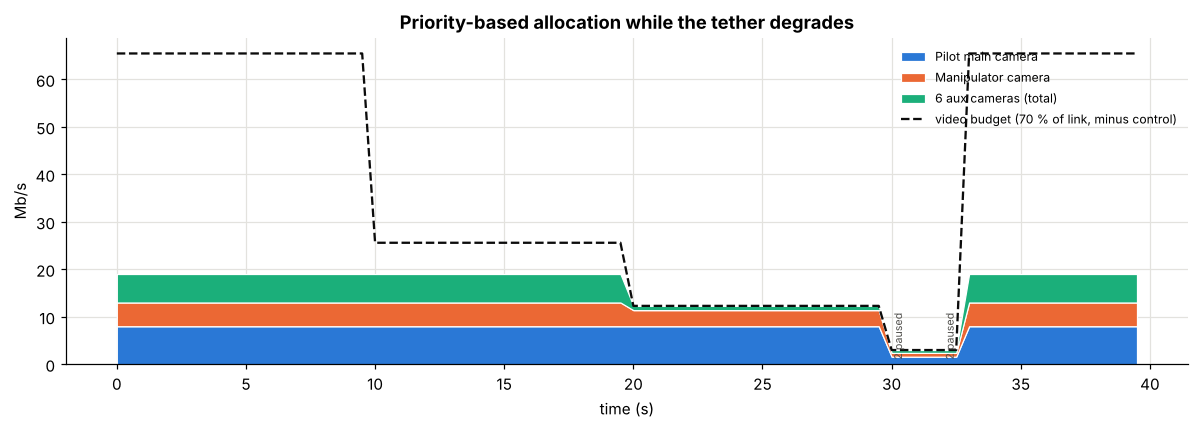

In [30]:
def allocate(budget, cams):
    """cams: list of dicts with name, priority (1 = highest), min, max (Mb/s). Returns {name: Mb/s} (0 = paused)."""
    alloc = {c["name"]: 0.0 for c in cams}; order = sorted(cams, key=lambda c: c["priority"]); left = budget
    for c in order:                                    # pass 1: minimums, highest priority first
        if left >= c["min"]: alloc[c["name"]] = c["min"]; left -= c["min"]
    for c in order:                                    # pass 2: top up to max, highest priority first
        if alloc[c["name"]] > 0:
            add = min(c["max"] - alloc[c["name"]], left); alloc[c["name"]] += add; left -= add
    return alloc

CAMS = ([{"name": "Pilot main camera", "priority": 1, "min": 1.5, "max": 8.0},
         {"name": "Manipulator camera", "priority": 2, "min": 0.8, "max": 5.0}] +
        [{"name": f"Aux camera {i}", "priority": 3 + i, "min": 0.15, "max": 1.0} for i in range(1, 7)])
t = np.arange(0, 40, 0.5)
capacity = np.where(t < 10, 100, np.where(t < 20, 40, np.where(t < 30, 20, np.where(t < 33, 6, 100))))
budget = capacity * HEADROOM / (1 + OVERHEAD["RTP/UDP"]) - 1.0     # 1 Mb/s reserved for control + telemetry
series = pd.DataFrame([allocate(b, CAMS) for b in budget], index=t)
groups = {"Pilot main camera": series["Pilot main camera"], "Manipulator camera": series["Manipulator camera"],
          "6 aux cameras (total)": series.filter(like="Aux").sum(axis=1)}
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(t, *groups.values(), labels=groups.keys(), colors=PALETTE[:3], edgecolor="white", linewidth=0.8)
ax.plot(t, budget, color="#0b0b0b", lw=1.5, ls="--", label="video budget (70 % of link, minus control)")
paused = series.filter(like="Aux").eq(0).sum(axis=1)
for tt, n in zip(t[::4], paused.values[::4]):
    if n: ax.text(tt, 1.5, f"{n} paused", fontsize=7, rotation=90, color="#52514e")
ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s"); ax.set_title("Priority-based allocation while the tether degrades")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

**Interpretation.** With fixed bitrates, a link drop congests **all** cameras at once — including the one the pilot is driving with. With priority allocation, the pilot's camera stays sharp, auxiliary cameras degrade gracefully, and some pause *visibly*. This needs (a) encoders whose bitrate can be changed at runtime (most hardware encoders and x264 via its API can; many IP cameras can via their HTTP/ONVIF API), (b) a measurement of available throughput (RTCP receiver reports, WebRTC's congestion control, or periodic probing), and (c) a UI that tells the truth about what each camera is doing.

<div align="center">

### Exercises

</div>

1. Choose the priorities for **your** mission tasks. Does the "pilot main camera" change during the mission?
2. What should happen to a paused camera in the UI? Write an acceptance criterion for it.
3. Which component in your system would run `allocate()` — the SBC, the topside laptop, or the browser? Justify.

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 9</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Latency: where does the time go?</h2>
</div>


**Question.** Why does the pilot see the gripper close *after* they pressed the button?

<div align="center">

### Four words that are often confused

</div>


<div align="center">

| Term | Meaning | Unit | Analogy (a conveyor belt of boxes) |
|---|---|---|---|
| **Frame rate (FPS)** | how many frames arrive per second | frames/s | how many boxes reach you per second |
| **Throughput / bitrate** | how many bits per second are delivered | Mb/s | total weight of boxes per second |
| **Bandwidth / capacity** | how many bits per second the link *could* carry | Mb/s | how wide the belt is |
| **Latency** | how long one frame takes from the scene to the screen | ms | how long one box spends on the belt |

</div>


A system can deliver a perfect 30 FPS **and** be two seconds late — the belt is just long. For piloting, **latency is usually more important than FPS**: humans can steer at 15 FPS with 100 ms of latency, but struggle at 60 FPS with 800 ms.

<div align="center">

### The latency chain

</div>


$$
L_{\text{glass-to-glass}} = L_{\text{capture}} + L_{\text{encode}} + L_{\text{packetize}} + L_{\text{network}} + L_{\text{jitter buffer}} + L_{\text{decode}} + L_{\text{render}} + L_{\text{display}}
$$

Typical contributors (to be **measured**, not assumed):

* **Capture:** exposure + sensor readout + USB/driver buffering. Often ~1 frame (33 ms at 30 FPS) or more; V4L2 drivers may queue several buffers.
* **Encode:** for x264 this is dominated by *how many frames the encoder holds back* (lookahead, B-frames, frame threads). We measure this below.
* **Network:** over a short wired tether this is tiny (< 1 ms per hop) *unless* queues build up because the link is congested — then it can grow to hundreds of ms.
* **Jitter buffer:** the receiver deliberately waits so that late packets still arrive in time. Players for "normal" video default to large buffers (VLC's network caching default is 1000 ms; HLS players typically buffer several seconds).
* **Decode, render, display:** a few ms to decode; then the browser/OS compositor and the monitor's refresh add ~1–2 display frames.

<div align="center">

### 9.1 Measuring encoder delay frame by frame (PyAV)

</div>


We feed frames into x264 **one at a time** and count how many frames go in before the first compressed packet comes out. That count × frame time is the latency the encoder adds by *design*, regardless of how fast the CPU is.

In [31]:
try:
    import av
    HAVE_AV = True
except ImportError:
    HAVE_AV = False
    print("PyAV not installed (pip install av) — skipping the frame-by-frame measurement; the budget below uses typical values.")

ENC_CONFIGS = {
    "x264 medium (defaults)":                 {"preset": "medium"},
    "x264 medium, no B-frames":               {"preset": "medium", "bf": "0"},
    "x264 medium, no B-frames, no lookahead": {"preset": "medium", "bf": "0", "x264-params": "rc-lookahead=0:sync-lookahead=0"},
    "x264 ultrafast":                         {"preset": "ultrafast"},
    "x264 veryfast + tune zerolatency":       {"preset": "veryfast", "tune": "zerolatency"},
}
enc_delay = {}
if HAVE_AV:
    src_frames = []
    with av.open(str(SRC)) as cont:
        for i, fr in enumerate(cont.decode(video=0)):
            src_frames.append(fr.reformat(format="yuv420p"))
            if i >= 89: break
    for label, opts in ENC_CONFIGS.items():
        ctx = av.CodecContext.create("libx264", "w")
        ctx.width, ctx.height, ctx.pix_fmt = W, H, "yuv420p"
        ctx.time_base = Fraction(1, FPS); ctx.framerate = Fraction(FPS, 1); ctx.options = dict(opts)
        first_out, times = None, []
        for i, fr in enumerate(src_frames):
            fr.pts = i
            t0 = time.perf_counter(); pkts = ctx.encode(fr); times.append(time.perf_counter() - t0)
            if pkts and first_out is None: first_out = i
        ctx.encode(None)  # flush
        held = (first_out if first_out is not None else len(src_frames))
        enc_delay[label] = {"frames held before first output": held, "delay from buffering (ms)": held * 1000 / FPS,
                            "mean time per encode() call (ms)": 1000 * np.mean(times[10:])}
    e9 = pd.DataFrame(enc_delay).T
    display(e9.style.format({"frames held before first output": "{:.0f}", "delay from buffering (ms)": "{:.0f}",
                             "mean time per encode() call (ms)": "{:.1f}"}))

,frames held before first output,delay from buffering (ms),mean time per encode() call (ms)
x264 medium (defaults),41,1367,10.7
"x264 medium, no B-frames",41,1367,12.7
"x264 medium, no B-frames, no lookahead",1,33,14.0
x264 ultrafast,1,33,2.2
x264 veryfast + tune zerolatency,0,0,8.1


**Interpretation.** With default settings x264 holds back tens of frames (rate-control lookahead, B-frame decisions, frame-level threading) — that is often **more than a second of latency added by configuration alone**. `-tune zerolatency` disables lookahead and B-frames and switches to slice-based threading, so a frame comes out (almost) as soon as it goes in. Hardware encoders (Jetson's NVENC block) have their own low-latency settings — check the encoder's properties with `gst-inspect-1.0 nvv4l2h264enc`.

<div align="center">

### 9.2 The jitter buffer trade-off

</div>


Packets do not arrive at perfectly regular intervals: queues in the switch, the SBC's network stack and the laptop all add variable delay (**jitter**). A receiver that displays frames *as soon as they arrive* shows stutter; one that waits too long adds latency. We simulate a tether with mostly small jitter and occasional 30–80 ms spikes (e.g. a CPU burst on the SBC).

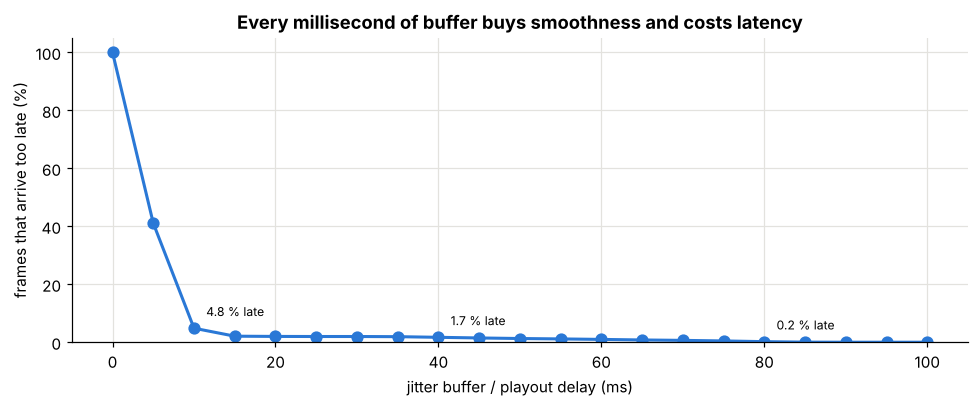

In [32]:
rng = np.random.default_rng(1)
n = 30 * 120                                             # two minutes at 30 FPS
base = 2.0                                                # ms, wire + switching
jitter = rng.gamma(2.0, 1.5, n)                           # small, everyday jitter
spikes = np.where(rng.random(n) < 0.02, rng.uniform(30, 80, n), 0)   # 2 % of frames hit a spike
delay = base + jitter + spikes
buffers = np.arange(0, 101, 5)
late_pct = [(delay > b).mean() * 100 for b in buffers]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(buffers, late_pct, "o-", color=PALETTE[0])
ax.set_xlabel("jitter buffer / playout delay (ms)"); ax.set_ylabel("frames that arrive too late (%)")
ax.set_title("Every millisecond of buffer buys smoothness and costs latency"); ax.set_ylim(bottom=0)
for b in (10, 40, 80):
    ax.annotate(f"{(delay > b).mean()*100:.1f} % late", (b, (delay > b).mean()*100), textcoords="offset points", xytext=(8, 8), fontsize=8)
plt.tight_layout(); plt.show()

<div align="center">

### 9.3 A latency budget for three pipelines — **ESTIMATE**

</div>


The numbers below are **typical orders of magnitude, not measurements of your system**. The encoder value of the H.264 pipelines comes from 9.1 when PyAV is available. The point is to see *which stage dominates* each design — then go and measure it (9.4).

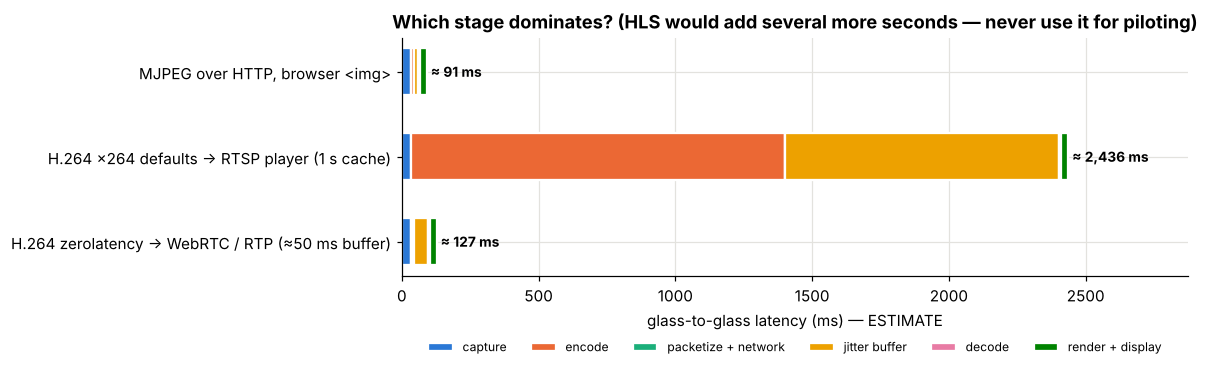

In [33]:
enc_default = enc_delay.get("x264 medium (defaults)", {}).get("delay from buffering (ms)", 1300)
enc_zl = enc_delay.get("x264 veryfast + tune zerolatency", {}).get("mean time per encode() call (ms)", 10)
STAGES = ["capture", "encode", "packetize + network", "jitter buffer", "decode", "render + display"]
BUDGETS = {   # ms — ESTIMATES (see text)
    "MJPEG over HTTP, browser <img>":           [33, 10, 3, 15, 5, 25],
    "H.264 x264 defaults → RTSP player (1 s cache)": [33, enc_default, 3, 1000, 8, 25],
    "H.264 zerolatency → WebRTC / RTP (≈50 ms buffer)": [33, enc_zl, 3, 50, 8, 25],
}
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (name, vals) in enumerate(BUDGETS.items()):
    left = 0
    for k, v in enumerate(vals):
        ax.barh(i, v, left=left, color=PALETTE[k], height=0.55, edgecolor="white", linewidth=1.5, label=STAGES[k] if i == 0 else None)
        left += v
    ax.text(left + 15, i, f"≈ {left:,.0f} ms", va="center", fontsize=9, fontweight="bold")
ax.set_yticks(range(len(BUDGETS)), BUDGETS.keys()); ax.invert_yaxis(); ax.set_xlabel("glass-to-glass latency (ms) — ESTIMATE")
ax.set_xlim(right=max(sum(v) for v in BUDGETS.values()) * 1.18)
ax.set_title("Which stage dominates? (HLS would add several more seconds — never use it for piloting)")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22)); plt.tight_layout(); plt.show()

<div align="center">

### 9.4 How to measure glass-to-glass latency on the real ROV (no special equipment)

</div>


1. On the **topside laptop**, open a millisecond clock (e.g. a full-screen stopwatch web page, or run `python3 -c "import time; [print(f'{time.time()%100:7.3f}', end='\r') for _ in iter(int, 1)]"` in a large-font terminal).
2. Point one ROV camera **at that screen** (on deck, before the dive).
3. Put the ROV's video window **next to** the clock on the same screen.
4. Take a photo of the screen with a phone. The difference between the real clock and the clock *inside the video* is the glass-to-glass latency.
5. Repeat ≥ 10 times, for each camera and each configuration. Report the **median and the worst value**, not the best.

Variants: do it with 1 camera streaming, then all 8 — if latency jumps, you have found a congestion or CPU problem. Do it while the thrusters run at full power — if it jumps, suspect power/USB issues.

<div align="center">

### Exercises

</div>

1. Which stage dominates *your* current system? Make a hypothesis, then measure.
2. Why does TCP-based streaming feel fine on the bench and become laggy during a mission? *(Hint: what happens to the TCP send buffer when the link briefly slows down?)*
3. Write a non-functional requirement for latency that is testable. (Example: "Glass-to-glass latency of the pilot camera ≤ 200 ms median and ≤ 300 ms worst case over 10 measurements, with all cameras streaming.")

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 10</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Hardware encoding</h2>
</div>


**Question.** Can the onboard computer encode in hardware, and how much does that change?

<div align="center">

### What the two boards actually have (verified against vendor documentation — see References)

</div>


<div align="center">

| | **NVIDIA Jetson Nano** (2019, Maxwell) | **Raspberry Pi 5** (BCM2712) |
|---|---|---|
| Hardware **encoder** | ✅ H.264 and H.265: up to 4K30 · 4× 1080p30 · 9× 720p30 *(NVIDIA spec)* | ❌ **none** — H.264 encoding is done in software (libx264) on the Cortex-A76 CPU *(Raspberry Pi white paper, 2026)* |
| Hardware **decoder** | ✅ H.264/H.265: up to 4K60 · 8× 1080p30 | ✅ **HEVC (H.265) only**, 4Kp60. No H.264 hardware decode |
| How to use the encoder | **GStreamer**: `nvv4l2h264enc`, `nvv4l2h265enc` (L4T Accelerated GStreamer). Also the Jetson Multimedia API (V4L2 M2M) | `libx264` via FFmpeg, GStreamer `x264enc`, or `rpicam-vid` (which uses libav/libx264 on Pi 5) |
| FFmpeg hardware encode | ❌ Upstream FFmpeg does **not** use the Nano's encoder. Community patches exist (`jetson-ffmpeg`, `h264_nvmpi`); NVIDIA's own FFmpeg package supports accelerated **decode** | ❌ (nothing to accelerate) |
| Software it runs | JetPack 4.x (Ubuntu 18.04). The Nano is supported up to JetPack 4.6.x | Raspberry Pi OS (Debian Bookworm/Trixie) |

</div>


> ⚠️ **Jetson Nano ≠ Jetson Orin Nano.** The newer *Orin* Nano has **no hardware video encoder**; NVIDIA states 1080p30 encoding is done with 1–2 CPU cores. Check which board you actually have: `cat /etc/nv_tegra_release` (L4T R32 = Nano/JetPack 4; R35/R36 = Orin).

**Measured Raspberry Pi 5 data point** (Raspberry Pi Ltd, *H.264 encoding performance on Raspberry Pi 5-series computers*, 2026): a single 1080p30 libx264 encode needed roughly **62–90 % of one core** in a low-latency (`ultrafast` + zerolatency) configuration and **98–153 %** in a higher-quality (`superfast`) configuration, depending on bitrate. The paper does **not** test multiple simultaneous streams or thermal behaviour — that is your experiment.

<div align="center">

### Deciding where to encode

</div>


<div align="center">

| Option | Good when | Watch out for |
|---|---|---|
| **In the camera** (IP cameras, UVC cameras with built-in H.264) | Cameras already produce H.264/H.265 with substreams; the SBC only forwards | You depend on the camera's encoder settings and quirks; check GOP, bitrate control and latency options |
| **On the SBC — hardware** (Jetson Nano) | USB cameras delivering raw/MJPEG; ≤ 4× 1080p30 or ≤ 9× 720p30 total | Shared encoder capacity; MJPEG input must be **decoded first** (Jetson has an `nvjpegdec`/`nvv4l2decoder` path for that) |
| **On the SBC — software** (Raspberry Pi 5, Orin Nano) | A few streams at modest resolution, `ultrafast` + zerolatency | CPU budget for control software; **thermal throttling** in a sealed enclosure |
| **On the topside laptop** | Re-encoding for recording or for the browser (e.g. transcoding to a codec the browser decodes) | It does not help the tether at all — the bits already crossed it |

</div>


<div align="center">

### 10.1 What can *this* machine do?

</div>


In [34]:
def board_model():
    for f in ("/proc/device-tree/model", "/sys/firmware/devicetree/base/model"):
        try: return Path(f).read_text(errors="ignore").strip("\x00\n ")
        except Exception: pass
    return platform.processor() or platform.machine()
IS_JETSON = Path("/etc/nv_tegra_release").exists()
MODEL = board_model(); IS_PI5 = "Raspberry Pi 5" in MODEL
print(f"Machine: {MODEL} | Jetson: {IS_JETSON} | Raspberry Pi 5: {IS_PI5} | cores: {CPU_CORES}")
if IS_JETSON: print(Path("/etc/nv_tegra_release").read_text().strip())

# Try each hardware encoder FFmpeg knows about with a 1-second test pattern. Being listed ≠ working!
TRY = {"h264_nvenc (NVIDIA desktop GPU)": ["-c:v", "h264_nvenc"],
       "h264_qsv (Intel Quick Sync)": ["-c:v", "h264_qsv"],
       "h264_vaapi (Intel/AMD via VA-API)": ["-vaapi_device", "/dev/dri/renderD128", "-vf", "format=nv12,hwupload", "-c:v", "h264_vaapi"],
       "h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)": ["-c:v", "h264_v4l2m2m"]}
rows = []
for name, args in TRY.items():
    pre = args[:2] if args[0] == "-vaapi_device" else []; post = args[2:] if pre else args
    r = run([FFMPEG, "-hide_banner", "-loglevel", "error", *pre, "-f", "lavfi", "-i", "testsrc2=size=1280x720:rate=30",
             "-t", "1", *post, "-f", "null", "-"], check=False)
    rows.append({"encoder": name, "listed in ffmpeg -encoders": HAS.get(name.split()[0], False),
                 "works on this machine": r["rc"] == 0, "error (first line)": "" if r["rc"] == 0 else (r["stderr"].strip().splitlines() or ["?"])[0][:90]})
display(pd.DataFrame(rows).style.hide(axis="index"))
print("→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.")

Machine: x86_64 | Jetson: False | Raspberry Pi 5: False | cores: 2


encoder,listed in ffmpeg -encoders,works on this machine,error (first line)
h264_nvenc (NVIDIA desktop GPU),True,False,[h264_nvenc @ 0x55b4bddc6d80] Cannot load libcuda.so.1
h264_qsv (Intel Quick Sync),True,False,[h264_qsv @ 0x55c66f102d80] Error creating a MFX session: -9.
h264_vaapi (Intel/AMD via VA-API),True,False,[AVHWDeviceContext @ 0x55cd8507df00] No VA display found for device /dev/dri/renderD128.
"h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)",True,False,[h264_v4l2m2m @ 0x55edd21b8d80] Could not find a valid device


→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.


<div align="center">

### 10.2 Software encoding capacity — the measurement you should repeat on the SBC

</div>


We encode frames with x264 (`ultrafast` and `veryfast`, both with `zerolatency`) on **one thread**, timing only the encoder, and measure how many frames per second one core sustains. Dividing by 30 FPS gives "how many 720p30 streams per core" — an *upper bound*, because real systems also capture, packetize, and run control software, and because a hot SBC throttles.

In [35]:
def one_core_fps(w, h, preset="ultrafast", n=60):
    """Frames per second that ONE thread of x264 sustains at w×h (encode time only)."""
    if HAVE_AV:
        frames = [f.reformat(width=w, height=h, format="yuv420p") for f in src_frames[:n]]
        ctx = av.CodecContext.create("libx264", "w"); ctx.width, ctx.height, ctx.pix_fmt = w, h, "yuv420p"
        ctx.time_base = Fraction(1, FPS); ctx.framerate = Fraction(FPS, 1); ctx.thread_count = 1
        ctx.options = {"preset": preset, "tune": "zerolatency", "b": "2500k"}
        t0 = time.perf_counter()
        for i, fr in enumerate(frames):
            fr.pts = i; ctx.encode(fr)
        ctx.encode(None); return n / (time.perf_counter() - t0)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}", "-c:v", "libx264",
             "-preset", preset, "-tune", "zerolatency", "-threads", "1", "-b:v", "2500k", "-f", "null", "-"])
    return N_FRAMES / r["wall_s"]          # fallback: includes scaling cost
cap = []
for (w, h) in ((640, 360), (1280, 720), (1920, 1080)):
    for pr in ("ultrafast", "veryfast"):
        fps1 = one_core_fps(w, h, pr)
        cap.append({"resolution": f"{w}×{h}", "preset": pr, "fps on ONE core": fps1, "30-FPS streams per core (upper bound)": fps1 / 30,
                    f"streams on {max(CPU_CORES-1,1)} spare cores": fps1 / 30 * max(CPU_CORES - 1, 1)})
display(pd.DataFrame(cap).style.format({"fps on ONE core": "{:.0f}", "30-FPS streams per core (upper bound)": "{:.1f}",
                                         f"streams on {max(CPU_CORES-1,1)} spare cores": "{:.1f}"}).hide(axis="index"))

resolution,preset,fps on ONE core,30-FPS streams per core (upper bound),streams on 1 spare cores
640×360,ultrafast,1061,35.4,35.4
640×360,veryfast,247,8.2,8.2
1280×720,ultrafast,385,12.8,12.8
1280×720,veryfast,84,2.8,2.8
1920×1080,ultrafast,155,5.2,5.2
1920×1080,veryfast,43,1.4,1.4


<div align="center">

### 10.3 Platform-specific instructions (run these on the board, in a terminal)

</div>


#### Jetson Nano (JetPack 4.x) — *requires the hardware*
```bash
cat /etc/nv_tegra_release                 # confirm L4T R32.x (Jetson Nano)
gst-inspect-1.0 | grep -E "nvv4l2|omx"    # list NVIDIA encoder/decoder elements
gst-inspect-1.0 nvv4l2h264enc             # every property: bitrate, iframeinterval, preset-level, maxperf-enable...

# USB camera (MJPEG) → hardware JPEG decode → hardware H.264 encode → RTP/UDP to the topside laptop
gst-launch-1.0 v4l2src device=/dev/video0 io-mode=2 ! image/jpeg,width=1280,height=720,framerate=30/1 ! \
  nvv4l2decoder mjpeg=1 ! nvvidconv ! 'video/x-raw(memory:NVMM),format=NV12' ! \
  nvv4l2h264enc bitrate=2500000 iframeinterval=30 insert-sps-pps=true maxperf-enable=1 ! \
  h264parse ! rtph264pay config-interval=1 pt=96 ! udpsink host=192.168.2.1 port=5600 sync=false

sudo tegrastats                           # watch NVENC / NVDEC activity, CPU load, temperatures
sudo jetson_clocks                        # (optional) lock clocks to max for benchmarking
```
Test each of 1, 2, 4, 6, 8 simultaneous pipelines and record `tegrastats` — you will find where the encoder or the USB bus saturates.

#### Raspberry Pi 5 — *requires the hardware; software encoding only*
```bash
cat /proc/device-tree/model; vcgencmd measure_temp; vcgencmd get_throttled   # 0x0 = never throttled
v4l2-ctl --list-devices; v4l2-ctl -d /dev/video0 --list-formats-ext           # what the USB camera can output

# USB camera (MJPEG) → software decode → x264 low latency → RTP/UDP
ffmpeg -f v4l2 -input_format mjpeg -video_size 1280x720 -framerate 30 -i /dev/video0 \
  -c:v libx264 -preset ultrafast -tune zerolatency -b:v 2500k -maxrate 2500k -bufsize 1250k -g 30 \
  -pix_fmt yuv420p -f rtp rtp://192.168.2.1:5600

# If the camera itself can output H.264 (some UVC cameras can), DON'T re-encode — just forward:
ffmpeg -f v4l2 -input_format h264 -video_size 1920x1080 -framerate 30 -i /dev/video0 -c:v copy -f rtp rtp://192.168.2.1:5600
```
While N streams run, record `top` (or `htop`) and `vcgencmd measure_temp` every few seconds **inside the closed enclosure**. A Pi 5 without active cooling throttles under sustained load.

#### Development laptop / PC with a GPU
```bash
ffmpeg -hide_banner -encoders | grep -E "nvenc|qsv|vaapi|amf|videotoolbox"
ffmpeg -i work/source.mkv -c:v h264_nvenc -preset p1 -tune ll -b:v 2500k out_nvenc.mp4      # NVIDIA
ffmpeg -i work/source.mkv -c:v h264_qsv -preset veryfast -b:v 2500k out_qsv.mp4             # Intel
ffmpeg -i work/source.mkv -c:v h264_videotoolbox -b:v 2500k out_vt.mp4                       # macOS
```

<div align="center">

### Exercises

</div>

1. On your SBC, find the maximum number of simultaneous 720p30 streams that run for **10 minutes** without dropped frames, without throttling, and with ≥ 1 CPU core free. That number is a real engineering constraint.
2. If your USB cameras deliver MJPEG, the SBC must *decode* before it can re-encode. Measure the cost of decode alone: `ffmpeg -f v4l2 -input_format mjpeg ... -i /dev/video0 -f null -`.
3. Would you choose a Jetson Nano or a Raspberry Pi 5 for an 8-camera ROV? Which measurements would change your mind?

<div align="center" style="background-color:#C00000; color:#ffffff; border-radius:14px; padding:14px 12px 12px; margin:22px 0 10px;">
<div style="font-size:11px; letter-spacing:4px; color:#ffd0d0;">EXPERIMENT 11</div>
<h2 style="color:#ffffff; margin:6px 0 0; border:none;">Final optimization challenge</h2>
</div>


> **Scenario.** You have **eight cameras**, a tether with **100 Mb/s** negotiated link speed (measured `iperf3` throughput: 94 Mb/s), an onboard computer with **limited encode capacity**, and a pilot who needs **responsive video** for docking, manipulation and inspection tasks.

**Requirements**

<div align="center">

| ID | Requirement | Type |
|---|---|---|
| R1 | The pilot camera is ≥ 1280×720 at ≥ 25 FPS | functional / quality |
| R2 | The manipulator camera is ≥ 1280×720 at ≥ 20 FPS whenever the gripper is in use | functional |
| R3 | All eight cameras remain *visible* (at least as thumbnails ≥ 5 FPS) | functional |
| R4 | Total video ≤ 70 % of measured throughput, leaving ≥ 2 Mb/s for control/telemetry | non-functional |
| R5 | Total encode load ≤ the onboard encoder budget you choose below | non-functional |
| R6 | Estimated glass-to-glass latency of the pilot camera ≤ 200 ms | non-functional |
| R7 | Recovery from a packet-loss burst within ≤ 1 s | non-functional |

</div>


**Your task.** Edit `design` below, run `evaluate(design)`, iterate until all checks pass, and then — most importantly — **write a short justification of each choice, citing the measurements from Experiments 3–10.** A configuration that passes the checker but cannot be justified does not pass the challenge.

In [36]:
ENCODER_BUDGETS = {   # pixel-rate budgets (pixels/s). Jetson Nano: 4×1080p30 ≈ 9×720p30 ≈ 249 Mpx/s (NVIDIA spec).
    "Jetson Nano hardware encoder": 4 * 1920 * 1080 * 30,
    # Raspberry Pi 5: ~0.65–0.9 core per 1080p30 ultrafast (RPi white paper). Assume 2.5 cores free for video, 0.8 core/1080p30:
    "Raspberry Pi 5 software (2.5 cores, ultrafast)": 2.5 / 0.8 * 1920 * 1080 * 30,
    "Cameras encode themselves (IP cameras)": float("inf"),
}

def evaluate(design, throughput_mbps=94, budget_name="Jetson Nano hardware encoder"):
    rows, ok = [], True
    total = sum(cam_mbps(c["codec"], c["res"], c["fps"]) for c in design["cameras"]) * (1 + OVERHEAD[design["transport"]])
    px_rate = sum(RES[c["res"]][0] * RES[c["res"]][1] * c["fps"] for c in design["cameras"] if c.get("encoded_on_sbc", True))
    pilot = next(c for c in design["cameras"] if c["role"] == "pilot"); manip = next(c for c in design["cameras"] if c["role"] == "manipulator")
    def check(rid, cond, detail):
        nonlocal ok; ok &= bool(cond); rows.append({"req": rid, "pass": "✅" if cond else "❌", "detail": detail})
    check("R1", RES[pilot["res"]][1] >= 720 and pilot["fps"] >= 25, f"pilot {pilot['res']}@{pilot['fps']}")
    check("R2", RES[manip["res"]][1] >= 720 and manip["fps"] >= 20, f"manipulator {manip['res']}@{manip['fps']}")
    check("R3", len(design["cameras"]) == 8 and all(c["fps"] >= 5 for c in design["cameras"]), f"{len(design['cameras'])} cameras, min fps {min(c['fps'] for c in design['cameras'])}")
    check("R4", total <= 0.7 * throughput_mbps and throughput_mbps - total >= 2, f"{total:.1f} Mb/s on the wire = {total/throughput_mbps:.0%} of {throughput_mbps}")
    check("R5", px_rate <= ENCODER_BUDGETS[budget_name], f"{px_rate/1e6:.0f} Mpx/s vs budget {ENCODER_BUDGETS[budget_name]/1e6:.0f} Mpx/s ({budget_name})")
    lat = 33 + design["encoder_delay_frames"] * 1000 / pilot["fps"] + 3 + design["jitter_buffer_ms"] + 8 + 25
    check("R6", lat <= 200, f"≈ {lat:.0f} ms (ESTIMATE: capture 33 + encoder hold + network 3 + buffer + decode 8 + display 25)")
    check("R7", design["gop_s"] <= 1.0 or design.get("intra_refresh", False), f"GOP {design['gop_s']} s, intra refresh: {design.get('intra_refresh', False)}")
    display(pd.DataFrame(rows).style.hide(axis="index"))
    print("ALL CHECKS PASS — now write the justification!" if ok else "Not yet — iterate.")
    return ok

# A deliberately naive starting design (it fails). Improve it.
design = {
    "transport": "RTP/UDP", "gop_s": 2.0, "intra_refresh": False, "encoder_delay_frames": 40, "jitter_buffer_ms": 200,
    "cameras": [{"role": "pilot", "codec": "H.264", "res": "1920×1080", "fps": 30},
                {"role": "manipulator", "codec": "H.264", "res": "1920×1080", "fps": 30}] +
               [{"role": "aux", "codec": "H.264", "res": "1920×1080", "fps": 30} for _ in range(6)],
}
evaluate(design)

req,pass,detail
R1,✅,pilot 1920×1080@30
R2,✅,manipulator 1920×1080@30
R3,✅,"8 cameras, min fps 30"
R4,✅,19.4 Mb/s on the wire = 21% of 94
R5,❌,498 Mpx/s vs budget 249 Mpx/s (Jetson Nano hardware encoder)
R6,❌,≈ 1602 ms (ESTIMATE: capture 33 + encoder hold + network 3 + buffer + decode 8 + display 25)
R7,❌,"GOP 2.0 s, intra refresh: False"


Not yet — iterate.


False

**Deliverable for each team (1 page):**

1. The final `design` and the `evaluate()` output.
2. For each requirement: *which measurement* supports your choice (cite the experiment and the number).
3. The **biggest risk** in your design and the test that would expose it on the real ROV.
4. What you would measure **first** on the actual vehicle to validate the model (hint: link speed, encoder capacity under heat, real bits-per-pixel of your cameras).

**Scoring (Activity 5 rubric, summarized):** correctness of the numbers (25 %), quality of justification from measurements (35 %), risk identification and test plan (25 %), clarity (15 %).

---
<div align="center">

## What to take back to the ROV

</div>


1. **Find out what you actually have** — USB or IP cameras, which codec, which protocol, which link speed. (ROV Experiments, E0.)
2. **Compression beats resolution cuts.** Moving from MJPEG to H.264 typically saves far more bandwidth than halving the resolution.
3. **Plan on peaks, not averages.** Use capped rate control for live video; keep ≥ 30 % headroom.
4. **Not every camera needs full quality all the time.** Main streams + substreams + priorities.
5. **Latency is designed.** Zero-latency encoder settings, short buffers, UDP-based transport, no HLS for piloting.
6. **Know your silicon.** Jetson Nano: hardware H.264/H.265 encoder via GStreamer. Raspberry Pi 5: software encoding only. Orin Nano: no encoder.
7. **Measure everything twice** — once in this notebook, once on the vehicle, inside the closed enclosure, with everything running.

In [37]:
# Summary of key numbers measured in this run (paste into your team's engineering log)
summary = {
    "machine": MODEL, "ffmpeg": run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0],
    "raw 1080p30 RGB24 (Mb/s)": round(raw_mbps(1920, 1080, 30, 24)),
    "H.264 CRF23 clip bitrate (Mb/s)": round(float(e3[(e3['mode']=='CRF') & (e3['setting']=='crf 23')]['bitrate_Mb/s'].iloc[0]), 2),
    f"SSIM target used": SSIM_TARGET,
    "bits/pixel at target": {k: round(v, 4) for k, v in CODEC_BPP.items()},
    "x264 default encoder hold (frames)": enc_delay.get("x264 medium (defaults)", {}).get("frames held before first output"),
    "x264 zerolatency hold (frames)": enc_delay.get("x264 veryfast + tune zerolatency", {}).get("frames held before first output"),
}
(WORK / "summary.json").write_text(json.dumps(summary, indent=2, default=str)); print(json.dumps(summary, indent=2, default=str))

{
  "machine": "x86_64",
  "ffmpeg": "ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers",
  "raw 1080p30 RGB24 (Mb/s)": 1493,
  "H.264 CRF23 clip bitrate (Mb/s)": 1.5,
  "SSIM target used": 0.981,
  "bits/pixel at target": {
    "H.264": 0.0454,
    "H.265": 0.0583,
    "MJPEG": 0.34,
    "AV1": 0.077
  },
  "x264 default encoder hold (frames)": 41,
  "x264 zerolatency hold (frames)": 0
}
